# Aplicación de RNN y LSTM al procesamiento del lenguaje natural

Este cuaderno aborda la **clasificación de mensajes SMS** mediante representaciones de texto y modelos recurrentes. Incluye la matemática necesaria para comprender los *embeddings* y su entrenamiento.

```{note}
La **teoría general de RNN, LSTM y BPTT** —incluidas las demostraciones sobre gradientes y flujo de error— se encuentra en el otro notebook. Aquí se recuperan únicamente los elementos necesarios para la aplicación de NLP.
```


## Aplicación: procesamiento del lenguaje natural

Esta sección presenta el ejemplo original de clasificación de mensajes **spam** y **ham**, con Word2Vec, Doc2Vec y una LSTM. La teoría general de las RNN y LSTM se conserva en el otro archivo.

```{figure} ./imgs/flujo_nlp_sms.png
:name: flujo-nlp-sms
:align: center

Flujo **recomendado** para separar entrenamiento, validación y prueba. Se presenta como guía conceptual; no representa literalmente todos los pasos del código original conservado.
```

**Base de datos:** [CSV en el repositorio de Kalbam](https://github.com/Kalbam/Datos/blob/main/spam_text_class.csv). El código lee su enlace directo: `https://raw.githubusercontent.com/Kalbam/Datos/main/spam_text_class.csv`.

```{warning}
El código original ajusta Word2Vec y el tokenizador sobre el DataFrame completo antes de separar entrenamiento y prueba. Por tanto, la evaluación puede presentar **fuga de información**. Además, se utiliza `Message_clean`, pero no aparece en las celdas de código originales una asignación que cree esa columna. Estas observaciones se documentan sin modificar el código.
```


In [308]:
import warnings
warnings.filterwarnings('ignore')
import sys
import tensorflow.keras
import pandas as pd
import sklearn as sk
import tensorflow as tf
tf.keras.utils.set_random_seed(42)             # fija Python, NumPy y TensorFlow a la vez
tf.config.experimental.enable_op_determinism() # fuerza operaciones deterministas en GPU

In [309]:
import tensorflow as tf
from tensorflow.python.platform import build_info as tf_build_info

print(f"Tensor Flow Version: {tf.__version__}")
print()
print(f"Python {sys.version}")
print(f"Pandas {pd.__version__}")
print(f"Scikit-Learn {sk.__version__}")
gpu = len(tf.config.list_physical_devices('GPU')) > 0
print("GPU is", "available" if gpu else "NOT AVAILABLE")

print()
print("=== Detalle de dispositivos físicos ===")
for device in tf.config.list_physical_devices('GPU'):
    print(device)
    details = tf.config.experimental.get_device_details(device)
    print(details)

print()
print("=== Versiones de CUDA/cuDNN con las que se compiló TensorFlow ===")
print(f"CUDA build version: {tf_build_info.build_info.get('cuda_version', 'N/A')}")
print(f"cuDNN build version: {tf_build_info.build_info.get('cudnn_version', 'N/A')}")

Tensor Flow Version: 2.21.0

Python 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:46:43) [GCC 14.3.0]
Pandas 2.3.1
Scikit-Learn 1.7.0
GPU is available

=== Detalle de dispositivos físicos ===
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
{'compute_capability': (8, 9), 'device_name': 'NVIDIA GeForce RTX 4070'}

=== Versiones de CUDA/cuDNN con las que se compiló TensorFlow ===
CUDA build version: 12.5.1
cuDNN build version: 9


Iniciamos verificando que TensorFlow está correctamente instalado y puede utilizar la GPU disponible.

La librería `gensim` utilizada en esta implementación debe instalarse con:

```
pip install gensim
```

> Usamos gensim 4.x (no 3.8.3). La API de Doc2Vec/Word2Vec es prácticamente igual, salvo que en la versión 4 ya no existe el parámetro `size` (se llama `vector_size`) y el atributo `wv.vocab` fue reemplazado por `wv.key_to_index`.

### Word2Vec: ¿de dónde salen realmente los embeddings?

Antes de usar Word2Vec como una "caja negra" de gensim, vale la pena entender **qué problema resuelve** y **de dónde salen los números** que forman un embedding.

### El principio distribucional

> *"Conocerás una palabra por la compañía que mantiene"*: J.R. Firth (1957)

Word2Vec parte de la **hipótesis distribucional: palabras que aparecen en contextos similares tienden a tener significados similares**. En vez de representar palabras como categorías discretas (one-hot encoding, donde "gato" y "perro" son igual de distintos que "gato" y "avión"), Word2Vec les asigna un **vector denso de números reales** (por ejemplo, 100 o 300 dimensiones) de forma que:

- Palabras que aparecen en contextos parecidos $\rightarrow$ vectores cercanos (similitud coseno alta).
- Las **relaciones semánticas quedan codificadas como direcciones en el espacio vectorial**. El ejemplo clásico:

$$\vec{v}(\text{rey}) - \vec{v}(\text{hombre}) + \vec{v}(\text{mujer}) \approx \vec{v}(\text{reina})$$



- Ejemplo ilustrativo con 4 dimensiones interpretables: `[realeza, género, riqueza, animalidad]`.

In [310]:
import numpy as np
np.set_printoptions(precision=2, suppress=True)

# [realeza, género(+masc/-fem), riqueza, animalidad]
vectores = {
    "rey":      np.array([0.9,  0.8, 0.7, 0.0]),
    "reina":    np.array([0.9, -0.8, 0.7, 0.0]),
    "hombre":   np.array([0.1,  0.9, 0.1, 0.0]),
    "mujer":    np.array([0.1, -0.9, 0.1, 0.0]),
    "principe": np.array([0.7,  0.85,0.5, 0.0]),
    "princesa": np.array([0.7, -0.85,0.5, 0.0]),
    "gato":     np.array([0.0,  0.0, 0.0, 0.9]),
    "avion":    np.array([-0.9, 0.0,-0.9,-0.9]),
}
for p, v in vectores.items():
    print(f"{p:10s} -> {v}")

rey        -> [0.9 0.8 0.7 0. ]
reina      -> [ 0.9 -0.8  0.7  0. ]
hombre     -> [0.1 0.9 0.1 0. ]
mujer      -> [ 0.1 -0.9  0.1  0. ]
principe   -> [0.7  0.85 0.5  0.  ]
princesa   -> [ 0.7  -0.85  0.5   0.  ]
gato       -> [0.  0.  0.  0.9]
avion      -> [-0.9  0.  -0.9 -0.9]


### Similitud coseno (álgebra lineal)

Mide el **ángulo** entre dos vectores, no su magnitud:

$$\cos(\theta) = \frac{\vec{a} \cdot \vec{b}}{\|\vec{a}\|\,\|\vec{b}\|}$$

**Ángulo pequeño $\rightarrow$ coseno cercano a 1 → palabras semánticamente parecidas.**

In [311]:
def cos_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

pares = [("rey","principe"), ("rey","reina"), ("gato","avion")]
for a, b in pares:
    print(f"cos({a}, {b}) = {cos_sim(vectores[a], vectores[b]):.2f}")

cos(rey, principe) = 0.99
cos(rey, reina) = 0.34
cos(gato, avion) = -0.58


### La analogía vectorial: resta + suma

$$\vec{v}(\text{rey}) - \vec{v}(\text{hombre}) + \vec{v}(\text{mujer})$$

- **rey − hombre** cancela el componente "masculino" y deja aislada la dirección de **realeza**.
- **+ mujer** inyecta la dirección "femenina".
- El resultado es cercano a **reina**, pero en este ejemplo **princesa** tiene una similitud coseno ligeramente mayor.

In [312]:
resultado = vectores["rey"] - vectores["hombre"] + vectores["mujer"]
print("Resultado:", resultado)
print("Reina    :", vectores["reina"])
print()
for p, v in vectores.items():
    if p not in ("rey","hombre","mujer"):
        print(f"cos(resultado, {p:10s}) = {cos_sim(resultado, v):.4f}")

Resultado: [ 0.9 -1.   0.7  0. ]
Reina    : [ 0.9 -0.8  0.7  0. ]

cos(resultado, reina     ) = 0.9942
cos(resultado, principe  ) = 0.0709
cos(resultado, princesa  ) = 0.9978
cos(resultado, gato      ) = 0.0000
cos(resultado, avion     ) = -0.6091


### Visualización de los vectores

Proyectamos en el plano **Realeza (eje X)** vs **Género (eje Y)**: las 2 dimensiones más ilustrativas.

Las flechas punteadas grises muestran el camino de la analogía: partiendo de `rey`, restamos `hombre` (☆ punto intermedio) y sumamos `mujer`, llegando al vector de la analogía (estrella naranja), cercano a `reina` y `princesa`.

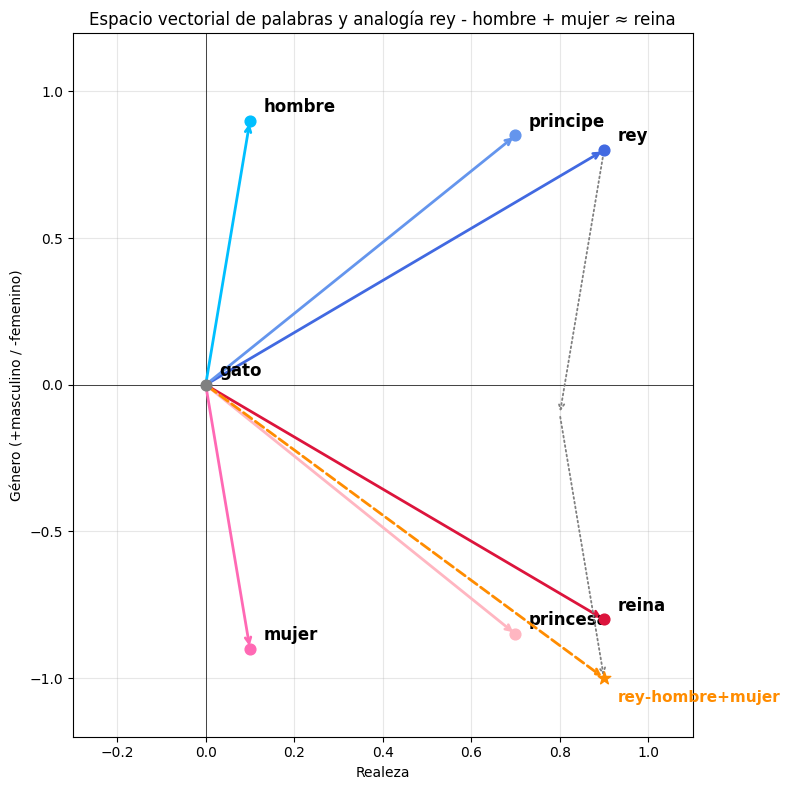

In [313]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
coords = {p: v[:2] for p, v in vectores.items() if p != "avion"}

colores = {
    "rey": "royalblue", "reina": "crimson", "hombre": "deepskyblue",
    "mujer": "hotpink", "principe": "cornflowerblue", "princesa": "lightpink",
    "gato": "gray"
}

for p, (x, y) in coords.items():
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=colores.get(p, "black"), lw=2))
    ax.scatter(x, y, color=colores.get(p, "black"), s=60, zorder=5)
    ax.text(x + 0.03, y + 0.03, p, fontsize=12, fontweight="bold")

res = resultado[:2]
ax.annotate("", xy=(res[0], res[1]), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color="darkorange", lw=2, linestyle="dashed"))
ax.scatter(res[0], res[1], color="darkorange", s=90, marker="*", zorder=6)
ax.text(res[0] + 0.03, res[1] - 0.08, "rey-hombre+mujer", fontsize=11, color="darkorange", fontweight="bold")

paso1 = vectores["rey"][:2] - vectores["hombre"][:2]
ax.annotate("", xy=paso1, xytext=vectores["rey"][:2],
            arrowprops=dict(arrowstyle="->", color="gray", lw=1.3, linestyle="dotted"))
ax.annotate("", xy=res, xytext=paso1,
            arrowprops=dict(arrowstyle="->", color="gray", lw=1.3, linestyle="dotted"))

ax.axhline(0, color="black", lw=0.5)
ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("Realeza")
ax.set_ylabel("Género (+masculino / -femenino)")
ax.set_title("Espacio vectorial de palabras y analogía rey - hombre + mujer ≈ reina")
ax.set_xlim(-0.3, 1.1)
ax.set_ylim(-1.2, 1.2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Interpretación geométrica

Estos vectores son **artificiales**. La analogía obtiene coseno $0.9942$ con reina y $0.9978$ con princesa; no demuestra que reina sea el vecino más cercano. Los embeddings reales dependen del corpus y pueden reflejar sesgos.


### ¿Cómo se obtienen esos vectores? Una red neuronal muy simple

Word2Vec **no** busca directamente vectores parecidos; en realidad entrena una red neuronal poco profunda para resolver una **tarea de predicción auxiliar**, y los embeddings son un **subproducto**: los pesos aprendidos por esa red.

Existen dos arquitecturas (ambas implementadas en gensim):

| Arquitectura | Tarea que resuelve | Ventaja |
|---|---|---|
| **CBOW** (Continuous Bag of Words) | Predecir la palabra central a partir de las palabras de su contexto | Más rápido, mejor con palabras frecuentes |
| **Skip-gram** | Predecir las palabras de contexto a partir de la palabra central | Mejor con palabras poco frecuentes y corpus pequeños |

**Arquitectura de la red (Skip-gram):**

```{figure} ./imgs/arquitectura_skipgram.png
:name: word2vec_arquitectura
:align: center

Arquitectura Word2Vec.
```

- $V$ = tamaño del vocabulario (cuántas palabras distintas hay).
- $D$ = dimensión del embedding que elegimos (ej. 100, 300).
- $W_1$ es una matriz $V \times D$: **cada fila de $W_1$ es el embedding de una palabra**. ¡Este es el origen de los embeddings!
- $W_2$ es una matriz $D \times V$ usada solo durante el entrenamiento (se descarta después).

```{admonition} Entrada y salida de Skip-gram
:class: tip

Skip-gram utiliza una **palabra central** para predecir palabras de su contexto; no necesariamente reconstruye la entrada. Las probabilidades dependen del modelo y del corpus. La misma palabra puede aparecer como contexto en otra posición.
```


### Skip-gram: qué entra, qué sale y dónde está el embedding

**Qué entra y qué sale.** Entra "gato" como vector one-hot. No sale una palabra, sino una **distribución de probabilidad** sobre todo el vocabulario $V$ (suma 1). Cada valor responde: *dado que "gato" es la palabra central, ¿qué tan probable es que la palabra de esa fila aparezca en su contexto?* Un valor como $0.60$ sería hipotético: la probabilidad depende del modelo y del corpus. **La red no convierte gato en perro: `Skip-gram` predice vecinos, no traduce ni sustituye**. Entrada y salida comparten el mismo vocabulario.

**De dónde sale el embedding.**

- $W_1 \in \mathbb{R}^{V \times D}$ es la **tabla de embeddings**: una fila por palabra.
- La capa oculta $\mathbf{h}$ no es una matriz aprendida aparte: es una **copia de la fila de $W_1$** seleccionada por el one-hot (de ahí "selecciona una fila").
- $W_2 \in \mathbb{R}^{D \times V}$ contiene los vectores de **contexto**. Solo sirve para calcular las puntuaciones, y en Word2Vec estándar se descarta al terminar (a veces se promedia con $W_1$).

Con $D = 4$, el embedding de "gato" es

$$
\mathbf{w}_{\text{gato}} = W_1[\text{gato}, :] = \mathbf{h} = [0.05,\ 0.02,\ 0.01,\ 0.95]
$$

Para cualquier otra palabra (por ejemplo "perro") basta poner el 1 en su posición: la capa oculta mostrará su fila de $W_1$.

```{admonition} Regla para recordar
:class: tip
Al terminar el entrenamiento se guarda $W_1$. **El embedding de la palabra $i$ es la fila $i$ de $W_1$**. La capa oculta es solo el lugar donde esa fila aparece durante el cálculo.
```

### Gradientes de Skip-gram con softmax completo

El modelo **Skip-gram** aprende a partir de pares formados por una palabra central
y una palabra de contexto {cite}`mikolov2013distributed`. Para hacer explícita la
retropropagación, consideremos una formulación didáctica con **softmax completo**.

Sean $V$ el tamaño del vocabulario, $D$ la dimensión de los embeddings y $(c,t)$
un par observado. Usamos la siguiente convención:

| **Símbolo** | **Función** | **Dimensión** |
|:---|:---|:---|
| $x_c$ | Vector *one-hot* de la palabra central. | $\mathbb{R}^{V}$ |
| $W_1$ | Matriz de embeddings de entrada. | $\mathbb{R}^{V\times D}$ |
| $h=W_1^{\top}x_c$ | Embedding de la palabra central. | $\mathbb{R}^{D}$ |
| $W_2$ | Matriz de pesos de salida. | $\mathbb{R}^{D\times V}$ |
| $u=W_2^{\top}h$ | Vector de *logits*. | $\mathbb{R}^{V}$ |
| $p$ | Probabilidades de contexto obtenidas con softmax. | $\mathbb{R}^{V}$ |
| $y$ | Etiqueta *one-hot* de la palabra de contexto observada. | $\mathbb{R}^{V}$ |

La probabilidad de la palabra $j$ y la pérdida del par observado son:

$$
p_j=\frac{e^{u_j}}{\sum_{k=1}^{V}e^{u_k}},
\qquad
L=-\sum_{j=1}^{V}y_j\log p_j=-\log p_t.
$$

```{prf:theorem} Gradientes de Skip-gram
:label: nlp-skipgram-gradientes

Bajo la formulación anterior y con $e:=p-y$, los gradientes para un par son:

$$
\nabla_uL=e,
\qquad
\frac{\partial L}{\partial W_2}=he^{\top},
\qquad
\nabla_hL=W_2e,
\qquad
\frac{\partial L}{\partial W_1}=x_c(W_2e)^{\top}.
$$
```

```{admonition} ¿Por qué se utiliza este procedimiento?
:class: note

La pérdida depende de $W_1$ y $W_2$ a través de una **cadena de operaciones**:
selección del embedding, cálculo de logits, softmax y entropía cruzada. Por ello,
se comienza en la pérdida y se aplica la **regla de la cadena** en sentido inverso.
```

```{prf:proof}
**Gradiente respecto a los logits.** Como la componente objetivo es $t$:

$$
L=-\log\left(\frac{e^{u_t}}{\sum_k e^{u_k}}\right)
=-u_t+\log\left(\sum_k e^{u_k}\right).
$$

Para una componente arbitraria $u_j$:

$$
\frac{\partial L}{\partial u_j}
=-\mathbf{1}_{\{j=t\}}
+\frac{e^{u_j}}{\sum_k e^{u_k}}
=p_j-y_j.
$$

Por tanto, $\nabla_uL=p-y=e$.

**Gradiente respecto a la matriz de salida.** Como
$u_j=\sum_{r=1}^{D}W_{2,rj}h_r$, se cumple
$\partial u_j/\partial W_{2,rj}=h_r$. Entonces:

$$
\frac{\partial L}{\partial W_{2,rj}}=h_r e_j,
\qquad
\frac{\partial L}{\partial W_2}=he^{\top}.
$$

El producto tiene dimensión $D\times V$, igual que $W_2$.

**Gradiente respecto al embedding.** Para cada componente $h_r$:

$$
\frac{\partial L}{\partial h_r}
=\sum_{j=1}^{V}\frac{\partial L}{\partial u_j}
\frac{\partial u_j}{\partial h_r}
=\sum_{j=1}^{V}e_jW_{2,rj}.
$$

En forma vectorial, $\nabla_hL=W_2e\in\mathbb{R}^{D}$.

**Gradiente respecto a la matriz de entrada.** Como
$h_r=\sum_{i=1}^{V}W_{1,ir}x_{c,i}$:

$$
\frac{\partial L}{\partial W_{1,ir}}
=x_{c,i}(W_2e)_r,
\qquad
\frac{\partial L}{\partial W_1}=x_c(W_2e)^{\top}.
$$

El producto tiene dimensión $V\times D$. Como $x_c$ es *one-hot*, **solo la
fila correspondiente a la palabra central** recibe una contribución no nula de
este par. Para un lote, las contribuciones de todos los pares se suman o promedian
según la definición de la pérdida.
```

#### Ejemplo numérico

Tomemos $V=3$, $D=2$, la primera palabra como central y la tercera como contexto:

$$
W_1=
\begin{bmatrix}
0.2&-0.3\\
-0.1&0.4\\
0.3&0.1
\end{bmatrix},
\qquad
W_2=
\begin{bmatrix}
0.1&-0.2&0.3\\
0.2&0.1&-0.1
\end{bmatrix}.
$$

La entrada selecciona la primera fila de $W_1$. La propagación produce:

$$
h=\begin{bmatrix}0.2\\-0.3\end{bmatrix},
\quad
u=\begin{bmatrix}-0.04\\-0.07\\0.09\end{bmatrix},
\quad
p\approx\begin{bmatrix}0.321619\\0.312113\\0.366268\end{bmatrix}.
$$

Para $y=[0,0,1]^{\top}$, la pérdida y el error en los logits son:

$$
L=-\log(0.366268)\approx1.004389,
\qquad
e\approx\begin{bmatrix}0.321619\\0.312113\\-0.633732\end{bmatrix}.
$$

Al sustituir en las expresiones demostradas:

$$
\frac{\partial L}{\partial W_2}
\approx
\begin{bmatrix}
0.064324&0.062423&-0.126746\\
-0.096486&-0.093634&0.190120
\end{bmatrix},
\qquad
\frac{\partial L}{\partial W_1}
\approx
\begin{bmatrix}
-0.220380&0.158908\\
0&0\\
0&0
\end{bmatrix}.
$$

```{important}
La primera fila de $W_1$ es la única que cambia para este par porque la primera
palabra fue seleccionada como central. Esta propiedad no implica que las demás
filas permanezcan fijas durante todo el entrenamiento.
```

**Alcance de la fuente.** El artículo citado introduce y estudia modelos de
representación distribucional. El resultado anterior es una **derivación didáctica**
para la convención y la pérdida especificadas; no se presenta como una transcripción
literal de un teorema del artículo.


### **Un paso numérico y verificación por diferencias finitas**

Tomamos tres palabras, dos dimensiones y un par central–contexto. Calculamos probabilidades, pérdida y gradientes; después verificamos cada elemento de ambos gradientes mediante diferencias finitas centrales:

$$\frac{\partial L}{\partial\theta_i}\approx\frac{L(\theta_i+\varepsilon)-L(\theta_i-\varepsilon)}{2\varepsilon}.$$

Esta verificación numérica se realiza en un punto y complementa, pero no reemplaza, la derivación analítica.

### La función de pérdida

Para cada par (palabra objetivo $w_t$, palabra de contexto $w_c$) observado en una ventana del corpus, la red calcula:

$$h = W_1^\top x_{w_t} \quad \text{(embedding actual de la palabra objetivo)}$$

$$u = W_2^\top h \quad \text{(puntuación para cada palabra del vocabulario)}$$

$$\hat{y} = \text{softmax}(u), \qquad \hat{y}_i = \frac{e^{u_i}}{\sum_{j=1}^{V} e^{u_j}}$$

Y se minimiza la entropía cruzada entre $\hat y$ y la palabra de contexto real (codificada one-hot). Como todos los componentes de $y$ son cero salvo $y_{w_c} = 1$, la entropía cruzada completa, $-\sum_i y_i \log \hat{y}_i$, se reduce a un solo término:

$$\mathcal{L} = -\log \hat{y}_{w_c}$$

Minimizar esta pérdida equivale a aumentar la probabilidad que la red asigna a la palabra de contexto observada. El descenso de gradiente ajusta $W_1$ y $W_2$ en ese sentido. **Durante el entrenamiento, las filas de $W_1$ (los embeddings) pueden organizarse de forma que palabras con contextos parecidos queden cerca en el espacio vectorial**, sin que nadie le haya dicho explícitamente al modelo qué significa cada palabra.

> En la práctica, gensim (y Word2Vec original) no usa softmax completo por ser muy costoso computacionalmente con vocabularios grandes; usa aproximaciones como **negative sampling** o **hierarchical softmax**. La idea conceptual es la misma.

### Gradientes del muestreo negativo

El **muestreo negativo** (*negative sampling*) permite entrenar con un par
observado y un conjunto de ejemplos negativos, en lugar de calcular el softmax
completo sobre todo el vocabulario {cite}`mikolov2013distributed`.

Para un embedding central $h$, un vector de contexto positivo $v_+$ y vectores
negativos $v_1,\dots,v_K$, definimos:

$$
s_+=v_+^{\top}h,
\qquad
s_j=v_j^{\top}h,
\qquad
\sigma(s)=\frac{1}{1+e^{-s}}.
$$

La pérdida para los negativos seleccionados es:

$$
L_{\mathrm{NS}}
=-\log\sigma(s_+)-\sum_{j=1}^{K}\log\sigma(-s_j).
$$

```{prf:theorem} Gradientes de las puntuaciones en muestreo negativo
:label: nlp-muestreo-negativo

Si las puntuaciones se consideran variables independientes, entonces:

$$
\frac{\partial L_{\mathrm{NS}}}{\partial s_+}=\sigma(s_+)-1,
\qquad
\frac{\partial L_{\mathrm{NS}}}{\partial s_j}=\sigma(s_j).
$$

Además, para los vectores del par y los negativos fijados:

$$
\nabla_hL_{\mathrm{NS}}
=(\sigma(s_+)-1)v_+ + \sum_{j=1}^{K}\sigma(s_j)v_j.
$$
```

```{admonition} Justificación del procedimiento
:class: note

Cada término de la pérdida depende de una **puntuación escalar**. Primero se
diferencia respecto a esa puntuación y después se utiliza la regla de la cadena
para volver al embedding $h$ y a los vectores de contexto.
```

```{prf:proof}
La derivada de la función sigmoide satisface:

$$
\sigma'(s)=\sigma(s)\bigl(1-\sigma(s)\bigr).
$$

Para el término positivo:

$$
\frac{d}{ds_+}\bigl[-\log\sigma(s_+)\bigr]
=-\frac{\sigma'(s_+)}{\sigma(s_+)}
=\sigma(s_+)-1.
$$

Para un término negativo, aplicamos la regla de la cadena al argumento $-s_j$:

$$
\begin{aligned}
\frac{d}{ds_j}\bigl[-\log\sigma(-s_j)\bigr]
&=\frac{\sigma'(-s_j)}{\sigma(-s_j)}\\
&=1-\sigma(-s_j)=\sigma(s_j).
\end{aligned}
$$

Las otras partes de la pérdida no dependen directamente de la puntuación
considerada, lo que demuestra las dos primeras expresiones.

Finalmente, $\nabla_hs_+=v_+$ y $\nabla_hs_j=v_j$. Al sumar los caminos que
llegan a $h$:

$$
\nabla_hL_{\mathrm{NS}}
=(\sigma(s_+)-1)v_+ + \sum_{j=1}^{K}\sigma(s_j)v_j.
$$

Si los vectores de contexto se tratan como parámetros independientes,
$\nabla_{v_+}L_{\mathrm{NS}}=(\sigma(s_+)-1)h$ y
$\nabla_{v_j}L_{\mathrm{NS}}=\sigma(s_j)h$.
```

Si una misma palabra aparece varias veces entre los negativos, o comparte un
parámetro con otro término, sus **contribuciones se acumulan** en el gradiente
de ese parámetro.

#### Ejemplo numérico

Supongamos dos negativos y las puntuaciones:

$$
s_+=\log 3,
\qquad
s_1=0,
\qquad
s_2=-\log 3.
$$

En consecuencia:

$$
\sigma(s_+)=0.75,
\qquad
\sigma(s_1)=0.50,
\qquad
\sigma(s_2)=0.25.
$$

Los gradientes escalares son:

$$
\frac{\partial L_{\mathrm{NS}}}{\partial s_+}=-0.25,
\qquad
\frac{\partial L_{\mathrm{NS}}}{\partial s_1}=0.50,
\qquad
\frac{\partial L_{\mathrm{NS}}}{\partial s_2}=0.25.
$$

Para ilustrar el gradiente vectorial, tomemos:

$$
h=\begin{bmatrix}1\\0\end{bmatrix},\qquad
v_+=\begin{bmatrix}\log3\\0\end{bmatrix},\qquad
v_1=\begin{bmatrix}0\\1\end{bmatrix},\qquad
v_2=\begin{bmatrix}-\log3\\2\end{bmatrix}.
$$

Estos vectores producen las puntuaciones indicadas y:

$$
\nabla_hL_{\mathrm{NS}}
=-0.25v_+ + 0.50v_1 + 0.25v_2
=\begin{bmatrix}-\tfrac12\log3\\1\end{bmatrix}
\approx\begin{bmatrix}-0.549306\\1\end{bmatrix}.
$$

```{important}
El muestreo negativo utiliza un **objetivo diferente** del softmax completo. Sus
puntuaciones sigmoidales no constituyen, por sí solas, una distribución de
probabilidad normalizada sobre todo el vocabulario.
```

**Alcance de la fuente.** La pérdida está relacionada con el método presentado por
Mikolov et al. La demostración anterior es una derivación de sus gradientes para
las variables e hipótesis indicadas; no es un teorema transcrito literalmente.


### Ejemplo numérico: implementando Skip-gram desde cero

Vamos a implementar un Word2Vec (Skip-gram) **minúsculo, sin gensim, solo con NumPy**, sobre un corpus de juguete de 4 oraciones. Así veremos con nuestros propios ojos cómo, partiendo de vectores aleatorios, el entrenamiento los organiza según el significado.

In [1]:
corpus = [
    "el gato duerme en el sofa",
    "el perro duerme en la cama",
    "el gato come pescado",
    "el perro come carne",
]

# Tokenización simple (separar por espacios)
tokenized = [s.split() for s in corpus]
vocab = sorted(set(w for sent in tokenized for w in sent))
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}

print("Vocabulario:", vocab)
print("Tamaño del vocabulario (V):", len(vocab))

Vocabulario: ['cama', 'carne', 'come', 'duerme', 'el', 'en', 'gato', 'la', 'perro', 'pescado', 'sofa']
Tamaño del vocabulario (V): 11


In [2]:
word2idx

{'cama': 0,
 'carne': 1,
 'come': 2,
 'duerme': 3,
 'el': 4,
 'en': 5,
 'gato': 6,
 'la': 7,
 'perro': 8,
 'pescado': 9,
 'sofa': 10}

In [3]:
idx2word

{0: 'cama',
 1: 'carne',
 2: 'come',
 3: 'duerme',
 4: 'el',
 5: 'en',
 6: 'gato',
 7: 'la',
 8: 'perro',
 9: 'pescado',
 10: 'sofa'}

**Paso 1: Generar pares (palabra objetivo, palabra de contexto).**

Con una ventana de tamaño 2, para cada palabra objetivo se toman hasta **2 palabras a la izquierda y 2 a la derecha**, es decir, hasta $2 \times 2 = 4$ palabras de contexto. Cerca del inicio o del final de la oración hay menos, porque la ventana se trunca.

Por ejemplo, en `"el gato duerme en el sofa"`, para la palabra objetivo `"duerme"` (posición 2) el contexto son las posiciones 0, 1, 3 y 4:

$$
\text{duerme} \rightarrow \{\text{el},\ \text{gato},\ \text{en},\ \text{el}\}
$$

La palabra "el" aparece dos veces porque ocupa dos posiciones distintas de la ventana. Cada aparición genera su propio par de entrenamiento.

```{admonition} Cuántos pares se generan
:class: tip
Una oración de $n$ palabras con ventana $w$ genera como máximo $2wn$ pares, y menos por el truncamiento en los bordes. Para esta oración ($n = 6$, $w = 2$) se generan 18 pares. El total de 56 reportado abajo corresponde a todo el corpus.
```

In [5]:
window = 2
pairs = []
for sent in tokenized:
    idxs = [word2idx[w] for w in sent]
    for center_pos, center_id in enumerate(idxs):
        for w in range(-window, window + 1):
            ctx_pos = center_pos + w
            if w == 0 or ctx_pos < 0 or ctx_pos >= len(idxs):
                continue
            pairs.append((center_id, idxs[ctx_pos]))

print("Ejemplos de pares (target -> contexto):")
for p in pairs[:18]:
    print(f"  {idx2word[p[0]]:8s} -> {idx2word[p[1]]}")
print(f"\nTotal de pares de entrenamiento generados: {len(pairs)}")

Ejemplos de pares (target -> contexto):
  el       -> gato
  el       -> duerme
  gato     -> el
  gato     -> duerme
  gato     -> en
  duerme   -> el
  duerme   -> gato
  duerme   -> en
  duerme   -> el
  en       -> gato
  en       -> duerme
  en       -> el
  en       -> sofa
  el       -> duerme
  el       -> en
  el       -> sofa
  sofa     -> en
  sofa     -> el

Total de pares de entrenamiento generados: 56


**Paso 2: Inicializar las matrices de pesos $W_1$ (embeddings) y $W_2$ (pesos de salida) al azar.**

Elegimos una dimensión de embedding pequeña ($D=5$) solo para poder inspeccionar los números fácilmente.

In [316]:
import numpy as np
np.random.seed(42)

V = len(vocab)   # tamaño del vocabulario
D = 5            # dimensión del embedding

W1 = np.random.uniform(-0.5, 0.5, (V, D))   # <- ESTA matriz, al final del entrenamiento, ES el embedding
W2 = np.random.uniform(-0.5, 0.5, (D, V))

print("W1 (embeddings iniciales, aleatorios) shape:", W1.shape)
print("W2 (pesos de salida) shape:", W2.shape)

W1 (embeddings iniciales, aleatorios) shape: (11, 5)
W2 (pesos de salida) shape: (5, 11)


**Paso 3: Entrenar con descenso de gradiente estocástico.**

Por cada par (target, contexto), hacemos forward pass, calculamos la pérdida (entropía cruzada) y actualizamos $W_1$ y $W_2$.

In [317]:
def one_hot(idx, size):
    v = np.zeros(size)
    v[idx] = 1
    return v

def softmax(x):
    e = np.exp(x - np.max(x))
    return e / e.sum()

lr = 0.05
losses = []
for epoch in range(300):
    total_loss = 0
    for target_id, context_id in pairs:
        # ---- FORWARD ----
        h = W1[target_id]                # embedding actual de la palabra objetivo, shape (D,)
        u = h @ W2                       # puntuación para cada palabra del vocabulario, shape (V,)
        y_pred = softmax(u)              # probabilidad de cada palabra de ser el contexto real

        # ---- LOSS (entropía cruzada) ----
        loss = -np.log(y_pred[context_id] + 1e-10)
        total_loss += loss

        # ---- BACKWARD ----
        y_true = one_hot(context_id, V)
        e = y_pred - y_true              # error, shape (V,)
        grad_W2 = np.outer(h, e)         # gradiente de W2
        grad_W1_row = W2 @ e             # gradiente de la fila de W1 correspondiente al target

        # ---- ACTUALIZACIÓN ----
        W2 -= lr * grad_W2
        W1[target_id] -= lr * grad_W1_row

    losses.append(total_loss / len(pairs))
    if epoch % 60 == 0:
        print(f"Epoch {epoch:3d}  Loss promedio: {losses[-1]:.4f}")

print("\nEntrenamiento terminado.")
print("W1 (V x D) ahora contiene los embeddings de palabras APRENDIDOS. Shape:", W1.shape)

Epoch   0  Loss promedio: 2.4129
Epoch  60  Loss promedio: 1.7252
Epoch 120  Loss promedio: 1.7240
Epoch 180  Loss promedio: 1.7244
Epoch 240  Loss promedio: 1.7254

Entrenamiento terminado.
W1 (V x D) ahora contiene los embeddings de palabras APRENDIDOS. Shape: (11, 5)


| Línea | Qué hace |
|---|---|
| `window = 2` | Número de palabras a considerar a cada lado de la palabra central. |
| `pairs = []` | Lista donde se acumulan los pares de todo el corpus. |
| `for sent in tokenized` | Recorre cada oración (lista de palabras). Los pares **nunca cruzan** de una oración a otra. |
| `idxs = [word2idx[w] for w in sent]` | Traduce las palabras de la oración a sus índices en el vocabulario. |
| `for center_pos, center_id in enumerate(idxs)` | Cada palabra hace de **central** una vez. `center_pos` es su posición y `center_id` su índice. |
| `for w in range(-window, window + 1)` | Recorre los desplazamientos $-2, -1, 0, +1, +2$ respecto a la palabra central. |
| `ctx_pos = center_pos + w` | Posición candidata a contexto. |
| `if w == 0 or ctx_pos < 0 or ctx_pos >= len(idxs): continue` | Descarta (i) la palabra central misma ($w=0$) y (ii) posiciones fuera de la oración, lo que trunca la ventana en los bordes. |
| `pairs.append((center_id, idxs[ctx_pos]))` | Guarda el par (central, contexto). |

**Impresión.** `idx2word[...]` convierte los índices de vuelta a texto para leerlos, y `{:8s}` alinea las palabras en 8 caracteres. `pairs[:12]` muestra solo los primeros 12 de los 56 pares.

**Ejemplo.** En `"el gato duerme en el sofa"` con centro `duerme` (posición 2), los desplazamientos $-2, -1, +1, +2$ dan las posiciones $0, 1, 3, 4$, es decir, los pares (duerme, el), (duerme, gato), (duerme, en), (duerme, el).

```{admonition} Puntos clave
:class: tip
- Cada oración de $n$ palabras aporta como máximo $2wn$ pares, y menos por el truncamiento en los bordes.
- No se eliminan duplicados: cada aparición cuenta como una observación de entrenamiento.
- El orden importa solo para definir la vecindad. Los pares resultantes no distinguen si el contexto estaba a la izquierda o a la derecha.
```

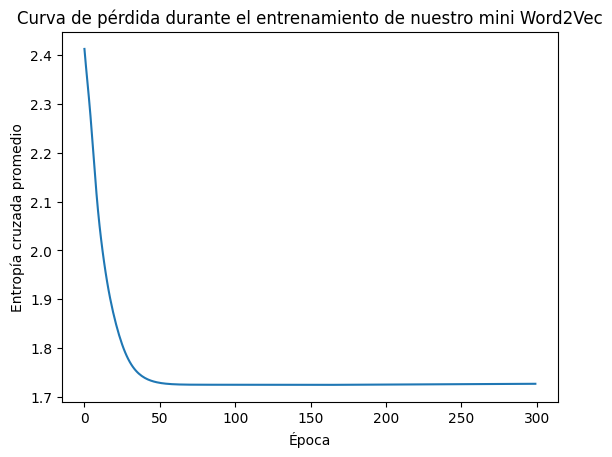

In [318]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.title("Curva de pérdida durante el entrenamiento de nuestro mini Word2Vec")
plt.xlabel("Época")
plt.ylabel("Entropía cruzada promedio")
plt.show()

**Paso 4:  Verificar que el embedding capturó relaciones semánticas.**

"gato" y "perro" aparecen en contextos parecidos ("el ___ duerme/come ..."), así que esperamos que sus vectores queden más cerca entre sí que, por ejemplo, "gato" y "cama" (que casi no coinciden en contexto).

In [319]:
def cos_sim(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

print("Similitud coseno entre pares de palabras (tras entrenar):")
print(f"  gato  - perro : {cos_sim(W1[word2idx['gato']],   W1[word2idx['perro']]):.4f}   (esperamos alta)")
print(f"  gato  - cama  : {cos_sim(W1[word2idx['gato']],   W1[word2idx['cama']]):.4f}   (esperamos baja)")
print(f"  come  - duerme: {cos_sim(W1[word2idx['come']],   W1[word2idx['duerme']]):.4f}")

Similitud coseno entre pares de palabras (tras entrenar):
  gato  - perro : 0.8813   (esperamos alta)
  gato  - cama  : -0.0583   (esperamos baja)
  come  - duerme: 0.2589


> **Conclusión clave**: **los embeddings no se diseñan a mano; emergen como los pesos $W_1$ de una red neuronal entrenada para resolver una tarea de predicción de contexto**. gensim hace exactamente esto (con optimizaciones como *negative sampling*, submuestreo de palabras frecuentes y multithreading), pero el principio matemático es el que acabamos de programar.

### Word2Vec con `gensim` sobre nuestro dataset de SMS

Ahora que entendemos el mecanismo interno, usamos la implementación optimizada de gensim (que usa negative sampling, C compilado y multithreading) sobre el dataset real de mensajes SMS.

In [320]:
import pandas as pd
import numpy as np
from tqdm import tqdm
tqdm.pandas(desc="progress-bar")
from gensim.models import Word2Vec
from sklearn import utils
from sklearn.model_selection import train_test_split
import re
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/Kalbam/Datos/main/spam_text_class.csv', delimiter=',', encoding='latin-1')
df = df[['Category', 'Message']]
df = df[pd.notnull(df['Message'])]
df.index = range(len(df))
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


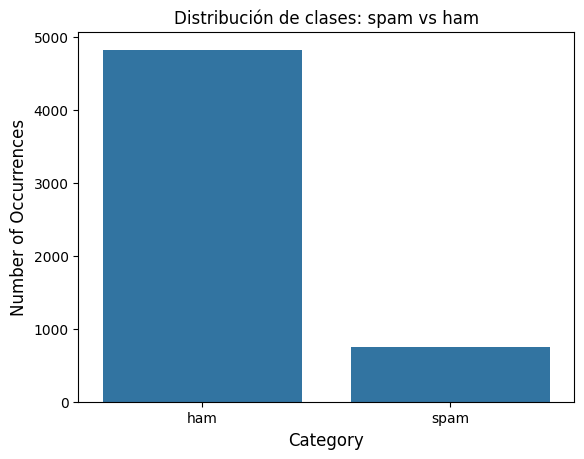

In [321]:
cnt_pro = df['Category'].value_counts()
sns.barplot(x=cnt_pro.index, y=cnt_pro.values)
plt.ylabel('Number of Occurrences', fontsize=12)
plt.xlabel('Category', fontsize=12)
plt.title('Distribución de clases: spam vs ham')
plt.show()

**Preprocesamiento de texto.** Limpiamos HTML, URLs y normalizamos a minúsculas.

In [ ]:
import re                                             # módulo de expresiones regulares (falta en tu fragmento)
from bs4 import BeautifulSoup                         # librería para interpretar HTML

def cleanText(text):                                  # recibe un mensaje crudo
    text = BeautifulSoup(text, "html.parser").text    # quita etiquetas HTML y deja solo el texto visible
    text = re.sub(r'\|\|\|', r' ', text)              # reemplaza cada "|||" por un espacio
    text = re.sub(r'http\S+', r'<URL>', text)         # reemplaza cada enlace por la marca <URL>
    text = text.lower()                               # pasa todo a minúsculas
    return text             

,Message,Message_clean
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...


### Expresiones regulares (regex) y su uso en el preprocesamiento

Una expresión regular es un **patrón** que describe un conjunto de cadenas de texto. El motor de regex recorre el texto buscando fragmentos que coincidan con el patrón, y con `re.sub(patrón, reemplazo, texto)` sustituye cada coincidencia por otro texto (o por nada).

**Elementos básicos.**

| Símbolo | Significado |
|---|---|
| `[abc]` | Un carácter cualquiera del conjunto (a, b o c). |
| `[a-z]` | Un carácter dentro del rango. |
| `[^...]` | **Negación**: cualquier carácter que *no* esté en el conjunto. |
| `\s`, `\d`, `\w` | Espacio en blanco, dígito, carácter de palabra. |
| `.` | Cualquier carácter (salvo salto de línea). |
| `*`, `+`, `?` | Cero o más, uno o más, cero o uno repeticiones. |
| `^`, `$` | Inicio y fin de la cadena. |
| `( )`, `\|` | Agrupación y alternativa ("o"). |

**Ejemplo típico de limpieza.**

```python
import re
texto = "El gato, duerme en el sofá!!! 123"
limpio = re.sub(r"[^a-záéíóúñü\s]", "", texto.lower())
# resultado: "el gato duerme en el sofá "
```

El patrón `[^a-záéíóúñü\s]` significa "todo carácter que **no** sea letra minúscula (con tildes y ñ) ni espacio". Cada coincidencia (`,`, `!`, `1`, `2`, `3`) se reemplaza por cadena vacía, es decir, se **elimina**.

**Por qué se eliminan esos caracteres.**

- **Evitar tokens duplicados.** Sin limpieza, `"gato"`, `"gato,"` y `"Gato"` serían tres palabras distintas del vocabulario, con tres embeddings distintos para un mismo concepto.
- **Reducir el tamaño del vocabulario $V$.** Menos entradas espurias implican matrices $W_1$ y $W_2$ más pequeñas y menos parámetros que estimar.
- **Reducir ruido y dispersión.** Signos de puntuación, números y símbolos aparecen en contextos poco informativos y diluyen la señal estadística de co-ocurrencia.
- **Normalizar.** Pasar a minúsculas (`lower()`) agrupa las variantes de una misma palabra.

```{admonition} Precauciones
:class: tip
- **En español hay que incluir las tildes y la ñ en el conjunto permitido**. Si se usa solo `[^a-z\s]`, "sofá" se convierte en "sof" y "año" en "ao".
- Eliminar puntuación también borra los límites de oración. Si la ventana de contexto no debe cruzar oraciones, conviene **separar en oraciones antes** de limpiar.
- Es una decisión de diseño: para tareas donde los números o los signos importan (fechas, emoticones, código), no deben eliminarse.
```

In [323]:
import nltk
nltk.download('punkt_tab', quiet=True)

def tokenize_text(text):
    tokens = []
    for sent in nltk.sent_tokenize(text):
        for word in nltk.word_tokenize(sent):
            if len(word) <= 0:
                continue
            tokens.append(word.lower())
    return tokens

sentences = df['Message_clean'].progress_apply(tokenize_text).tolist()
print(sentences[0])
print(sentences[12])

progress-bar: 100%|██████████| 5572/5572 [00:00<00:00, 20633.05it/s]

['go', 'until', 'jurong', 'point', ',', 'crazy', '..', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', '...', 'cine', 'there', 'got', 'amore', 'wat', '...']
['urgent', '!', 'you', 'have', 'won', 'a', '1', 'week', 'free', 'membership', 'in', 'our', 'â£100,000', 'prize', 'jackpot', '!', 'txt', 'the', 'word', ':', 'claim', 'to', 'no', ':', '81010', 't', '&', 'c', 'www.dbuk.net', 'lccltd', 'pobox', '4403ldnw1a7rw18']


- **Objetivo:** tokenizar cada mensaje de la columna `Message_clean` y obtener una lista de listas de tokens en minúsculas, lista para modelos como Word2Vec.
  - **Descarga de recursos:** `nltk.download('punkt_tab', quiet=True)` baja, sin mostrar mensajes, el modelo Punkt que necesitan los tokenizadores de NLTK.

- **Función `tokenize_text(text)`:** convierte un texto en una lista plana de tokens.
  - **Segmentación en oraciones:** `nltk.sent_tokenize(text)` divide el texto en oraciones.
  - **Segmentación en palabras:** `nltk.word_tokenize(sent)` divide cada oración en tokens, que incluyen los signos de puntuación.
  - **Filtrado y normalización:** se descartan los tokens vacíos (`len(word) <= 0`) y el resto se pasa a minúsculas con `word.lower()`.
  - **Salida:** una única lista por mensaje, de modo que se pierden los límites entre oraciones.

- **Aplicación al DataFrame:** `df['Message_clean'].progress_apply(tokenize_text).tolist()` ejecuta la función sobre cada fila mostrando una barra de progreso y devuelve `sentences`, una lista de listas de tokens.
  - **Inspección:** `print(sentences[0])` y `print(sentences[12])` muestran los tokens de los mensajes en las posiciones 0 y 12 para verificar el resultado.

```{note}
`progress_apply` requiere haber ejecutado antes `tqdm.pandas()`. Además, los signos de puntuación permanecen como tokens y la condición `len(word) <= 0` casi nunca se activa, porque `word_tokenize` no genera cadenas vacías. Si hay valores nulos (`NaN`) en `Message_clean`, la función lanzará un error.
```

Entrenamos dos modelos de Word2Vec: uno con arquitectura **CBOW** (`sg=0`) y otro **Skip-gram** (`sg=1`), para comparar.

In [324]:
w2v_cbow = Word2Vec(
    sentences=sentences,
    vector_size=100,   # dimensión de cada embedding de palabra
    window=5,          # tamaño de la ventana de contexto
    min_count=2,       # ignora palabras que aparecen menos de 2 veces (reduce ruido)
    sg=0,              # 0 = CBOW, 1 = Skip-gram
    workers=12,
    epochs=30,
    seed=42
)

w2v_sg = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,              # Skip-gram
    workers=4,
    epochs=30,
    seed=42
)

print("Vocabulario CBOW:", len(w2v_cbow.wv.key_to_index), "palabras")
print("Vocabulario Skip-gram:", len(w2v_sg.wv.key_to_index), "palabras")

Vocabulario CBOW: 4429 palabras
Vocabulario Skip-gram: 4429 palabras


- **Idea general:** los hiperparámetros están elegidos para un corpus de tamaño moderado (mensajes cortos) y para poder comparar de forma justa CBOW contra Skip-gram: se cambia solo `sg` y todo lo demás se mantiene igual.

- **`vector_size=100`:** dimensión del vector de cada palabra.

  - **El valor 100 no se calcula, se elige.** `vector_size` es un hiperparámetro fijado por el analista, sin fórmula que lo derive del corpus. Corresponde a $D$ en $W_1\in\mathbb{R}^{V\times D}$ (neuronas de la capa oculta) y define cuántos números describen a cada palabra. Con $V = 4429$ y $D = 100$, $W_1$ tiene $4429 \times 100 = 442{,}900$ parámetros (y $W_2$ otros tantos).

  - **En qué se basa la elección:**
    - **Convención de la literatura:** los trabajos originales usaron entre 100 y 300 dimensiones (300 en corpus enormes como Google News); es un punto de partida estándar, no un óptimo demostrado.
    - **Tamaño del corpus:** con pocos datos, más dimensiones aportan poca información útil y no hay ejemplos suficientes para estimarlas; con corpus muy grandes se justifican 200 a 300.
    - **Regla heurística $D \approx V^{1/4}$:** daría $4429^{1/4} \approx 8$; casi no se usa en Word2Vec porque los embeddings de palabras requieren más capacidad, pero sirve como referencia del extremo bajo.

  - **Cómo se decide en la práctica:** se prueban varios valores y se comparan con una tarea concreta (similitud de palabras, analogías o desempeño de un clasificador). Si pasar de 100 a 200 mejora poco, 100 es suficiente.

- **`window=5`:** número de palabras a cada lado de la palabra central que se consideran contexto.
  - **Por qué 5:** es el valor por defecto y equilibra dos efectos: ventanas pequeñas capturan relaciones sintácticas y de similitud funcional, y ventanas grandes capturan relaciones más temáticas. En mensajes cortos, una ventana mayor solo abarcaría casi todo el texto.

- **`min_count=2`:** se descartan las palabras que aparecen menos de dos veces.
  - **Por qué 2:** una palabra con una sola aparición no tiene contextos suficientes para aprender un vector fiable, y suelen ser errores de escritura o tokens raros. Filtrarlas reduce ruido y tamaño del vocabulario. Se usa un umbral bajo para no perder demasiado vocabulario en un corpus pequeño.

- **`sg=0` y `sg=1`:** selecciona la arquitectura.
  - **CBOW (`sg=0`):** predice la palabra central a partir del promedio de su contexto. Es más rápido y funciona bien con palabras frecuentes.
  - **Skip-gram (`sg=1`):** predice el contexto a partir de la palabra central. Es más lento, pero representa mejor las palabras poco frecuentes y suele rendir mejor en corpus pequeños.
  - **Por qué entrenar ambos:** para comparar la calidad de los embeddings resultantes con el mismo corpus y los mismos parámetros.

- **`workers=12`:** número de hilos de CPU usados en el entrenamiento.
  - **Por qué 12:** acelera el proceso y se ajusta a un equipo típico; no cambia el modelo, solo el tiempo de cómputo.

- **`epochs=30`:** número de pasadas completas por el corpus.
  - **Por qué 30:** el valor por defecto de `gensim` es 5, pero con pocos datos hacen falta más pasadas para que los vectores converjan. Más épocas mejoran el ajuste hasta un punto de rendimientos decrecientes, a cambio de mayor tiempo.

- **`seed=42`:** semilla del generador aleatorio para la inicialización de los vectores.
  - **Por qué:** favorece la reproducibilidad de los experimentos.

- **Verificación final:** `len(model.wv.key_to_index)` cuenta las palabras del vocabulario.
  - **Resultado esperado:** ambos modelos deberían mostrar el mismo tamaño, porque el vocabulario depende del corpus y de `min_count`, no de `sg`.

```{note}
Con `workers > 1`, fijar `seed=42` no garantiza resultados idénticos entre ejecuciones, porque el orden de procesamiento de los hilos introduce variación. Para reproducibilidad exacta se requiere `workers=1` (y, según la versión, fijar también `PYTHONHASHSEED`).
```

In [325]:
# Cada palabra ahora tiene un vector de 100 dimensiones. Este es el embedding "de dónde salen los números":
print("Embedding de la palabra 'urgent' (primeras 10 dimensiones de 100):")
print(w2v_sg.wv['urgent'][:10])
print("\nShape completo del vector:", w2v_sg.wv['urgent'].shape)

Embedding de la palabra 'urgent' (primeras 10 dimensiones de 100):
[-0.28  0.08  0.49 -0.01  0.09  0.33 -0.47  1.18 -1.18 -0.26]

Shape completo del vector: (100,)


In [326]:
print("Palabras más similares a 'urgent' (Skip-gram):")
for word, score in w2v_sg.wv.most_similar('urgent', topn=8):
    print(f"  {word:15s}  similitud={score:.4f}")

print("\nPalabras más similares a 'free' (Skip-gram):")
for word, score in w2v_sg.wv.most_similar('free', topn=8):
    print(f"  {word:15s}  similitud={score:.4f}")

Palabras más similares a 'urgent' (Skip-gram):
  09066350750      similitud=0.7553
  09066612661      similitud=0.7549
  abta             similitud=0.7200
  09061213237      similitud=0.7108
  complimentary    similitud=0.7033
  09066362231      similitud=0.6740
  gent             similitud=0.6713
  07xxxxxxxxx      similitud=0.6699

Palabras más similares a 'free' (Skip-gram):
  200              similitud=0.5482
  100              similitud=0.5437
  -sub             similitud=0.5369
  08002986906      similitud=0.5361
  unlimited        similitud=0.5351
  co               similitud=0.5349
  bluetooth        similitud=0.5253
  08002986030      similitud=0.5197


Los vecinos son **resultados empíricos**, no relaciones garantizadas. La proximidad puede reflejar similitud contextual sin implicar sinonimia.


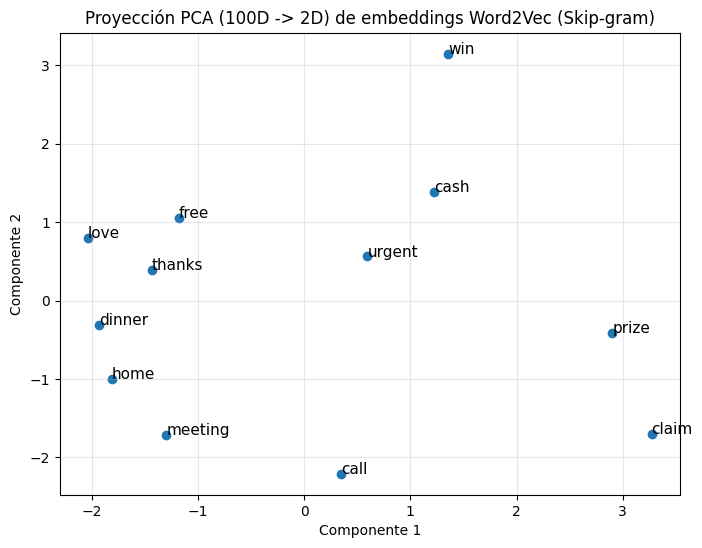

In [327]:
# Visualizamos el vecindario semántico con PCA (reducimos 100D -> 2D solo para graficar)
from sklearn.decomposition import PCA

words_to_plot = ['urgent', 'free', 'win', 'prize', 'claim', 'cash',
                  'love', 'home', 'thanks', 'meeting', 'dinner', 'call']
words_to_plot = [w for w in words_to_plot if w in w2v_sg.wv.key_to_index]

vectors = np.array([w2v_sg.wv[w] for w in words_to_plot])
coords = PCA(n_components=2, random_state=42).fit_transform(vectors)

plt.figure(figsize=(8, 6))
plt.scatter(coords[:, 0], coords[:, 1])
for i, w in enumerate(words_to_plot):
    plt.annotate(w, (coords[i, 0], coords[i, 1]), fontsize=11)
plt.title("Proyección PCA (100D -> 2D) de embeddings Word2Vec (Skip-gram)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.grid(alpha=0.3)
plt.show()

En esta proyección, cada punto es una palabra. **PCA de 100 a 2 dimensiones pierde información**: la proximidad visual no garantiza cercanía en el espacio original y el signo de los ejes es arbitrario. Interpreta los grupos después de observarlos.


### CBOW y Skip-gram

CBOW predice la palabra central desde el contexto; Skip-gram predice el contexto desde la palabra central. Su desempeño depende del corpus y de los hiperparámetros. En este experimento se utiliza **Skip-gram** {cite}`mikolov2013distributed`.


## Doc2Vec: extendiendo Word2Vec a documentos completos

Word2Vec nos da un vector **por palabra**. Pero para clasificar mensajes SMS completos (¿es spam o no?) necesitamos, en algún punto, un vector **por mensaje**. Existen dos estrategias:

1. **Promediar los embeddings de Word2Vec** de todas las palabras del mensaje (simple y efectivo).
2. **Doc2Vec** (Le & Mikolov, 2014): una extensión de **Word2Vec que aprende directamente un vector para cada documento, agregando un "pseudo-token" que identifica al documento durante el entrenamiento** (arquitectura *Distributed Memory*, análoga a CBOW pero con un vector de documento adicional en el contexto).

### Gradiente de una representación documental

**Doc2Vec**, o *Paragraph Vector*, aprende representaciones de fragmentos de texto
a partir de una tarea predictiva {cite}`le2014distributed`. Para estudiar el flujo
del gradiente, consideremos una versión didáctica de **PV-DM por promedio**.

Sean $d\in\mathbb{R}^{D}$ el vector documental y $v_1,\dots,v_m\in\mathbb{R}^{D}$
los vectores de contexto. Definimos:

$$
h=\frac{1}{m+1}\left(d+\sum_{j=1}^{m}v_j\right),
\qquad
u=W_2^{\top}h,
\qquad
p=\operatorname{softmax}(u),
\qquad
L=-\log p_t,
$$

con $W_2\in\mathbb{R}^{D\times V}$ y etiqueta objetivo *one-hot*
$y\in\mathbb{R}^{V}$.

```{prf:theorem} Gradiente del vector documental
:label: nlp-doc2vec-gradiente

Para la combinación por promedio definida arriba:

$$
\nabla_dL=\frac{1}{m+1}W_2(p-y).
$$

Si cada vector de contexto se considera una variable independiente, también se
cumple $\nabla_{v_j}L=\frac{1}{m+1}W_2(p-y)$.
```

```{admonition} Justificación del procedimiento
:class: note

El documento influye en la pérdida a través de la representación intermedia $h$.
Primero calculamos el gradiente que llega a $h$ desde la capa de salida; después
lo propagamos a través de la operación de **promedio**.
```

```{prf:proof}
Por el resultado de entropía cruzada con softmax:

$$
\nabla_uL=p-y.
$$

Como $u=W_2^{\top}h$, la regla de la cadena proporciona:

$$
\nabla_hL=W_2(p-y)\in\mathbb{R}^{D}.
$$

Ahora bien, cada componente de $h$ depende de la componente correspondiente de
$d$ con factor $1/(m+1)$. Por tanto:

$$
\frac{\partial h}{\partial d}=\frac{1}{m+1}I_D.
$$

Con la convención de gradientes columna:

$$
\nabla_dL
=\left(\frac{\partial h}{\partial d}\right)^{\!\top}\nabla_hL
=\frac{1}{m+1}W_2(p-y).
$$

Para cada $v_j$ el jacobiano del promedio es también $I_D/(m+1)$, de donde
resulta la expresión para $\nabla_{v_j}L$.
```

Si un mismo vector de palabra participa varias veces, sus aportes se **suman**.
Con una combinación por suma o concatenación, los jacobianos y gradientes son
distintos.

#### Ejemplo numérico

Consideremos $D=2$, dos palabras posibles de salida y un vector de contexto
$m=1$. Sean:

$$
d=\begin{bmatrix}0\\0\end{bmatrix},\qquad
v_1=\begin{bmatrix}0\\0\end{bmatrix},\qquad
W_2=\begin{bmatrix}1&0\\0&1\end{bmatrix},\qquad
y=\begin{bmatrix}1\\0\end{bmatrix}.
$$

Como $h=[0,0]^{\top}$, los logits son cero y $p=[0.5,0.5]^{\top}$. Por ello:

$$
\nabla_dL
=\frac12W_2(p-y)
=\begin{bmatrix}-0.25\\0.25\end{bmatrix}.
$$

Si actualizamos **solo $d$** con tasa $\eta=0.2$, manteniendo los demás valores
fijos:

$$
d_{\text{nuevo}}
=d-0.2\nabla_dL
=\begin{bmatrix}0.05\\-0.05\end{bmatrix}.
$$

En este ejemplo, la pérdida pasa de aproximadamente $0.693147$ a $0.668460$.
Una disminución para este paso no garantiza que cualquier tasa de aprendizaje
disminuya la pérdida en otros casos.

```{important}
La etiqueta o identificador de documento no es una **clase**. Para documentos
nuevos, el vector se infiere usando el modelo aprendido. La implementación concreta
puede utilizar variantes de agregación u objetivos de entrenamiento diferentes de
esta ilustración con softmax completo.
```

**Alcance de la fuente.** Le y Mikolov presentan *Paragraph Vector*. El resultado
demostrado aquí es una **adaptación algebraica** para el promedio, el softmax y la
pérdida definidos en esta sección, no un teorema citado literalmente del artículo.


In [328]:
from gensim.models.doc2vec import TaggedDocument, Doc2Vec
from sklearn import utils

train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)

train_tagged = train_df.apply(
    lambda r: TaggedDocument(words=tokenize_text(r['Message_clean']), tags=[str(r.name)]), axis=1)
test_tagged = test_df.apply(
    lambda r: TaggedDocument(words=tokenize_text(r['Message_clean']), tags=[str(r.name)]), axis=1)

print(train_tagged.values[0])

TaggedDocument<['reply', 'to', 'win', 'â£100', 'weekly', '!', 'where', 'will', 'the', '2006', 'fifa', 'world', 'cup', 'be', 'held', '?', 'send', 'stop', 'to', '87239', 'to', 'end', 'service'], ['1978']>


- **Qué es `TaggedDocument`**: tupla nombrada de gensim con dos campos, `words` y `tags`. Es el **formato de entrada obligatorio de Doc2Vec**.
  - **`words`: lista de tokens del texto**. Un token es un **fragmento de texto** (palabra, símbolo o número escrito como texto), **no un número que ya sea un vector**. Son cadenas de caracteres (*strings*).
    - Ejemplo: el mensaje `"Reply to win £100 weekly!"` se convierte en `words=['reply', 'to', 'win', '£100', 'weekly', '!']`.
    - Los números (vectores) aparecen después: Doc2Vec toma esos tokens y **aprende** un vector numérico para cada palabra y para cada documento.

  - **`tags`: lista de identificadores del documento**. Un identificador es un **nombre o código único** que sirve para reconocer al documento, igual que una cédula o un código de estudiante. También es **texto**, no el vector.
    - Ejemplo: si el mensaje está en la fila 5571 del DataFrame, `tags=['5571']`.
    - Ese `'5571'` es solo la **etiqueta**. El vector que el modelo aprende bajo esa etiqueta se recupera con `model.dv['5571']`, y devuelve algo como `array([0.12, -0.53, 0.88, ...])`.


- **Para qué sirve el tag**: Doc2Vec aprende **un vector por cada tag**, además de los vectores de palabras. El tag es la llave para recuperar ese vector (`model.dv['123']`).
  - **Tag único por mensaje** (`tags=[str(r.name)]`): cada mensaje obtiene su propio vector, que es lo necesario para clasificar mensajes.
  - **Tag por categoría** (`tags=[categoría]`, el error corregido): todos los mensajes de una clase comparten un solo vector, y el clasificador posterior queda inútil.
  - **Varios tags a la vez** (`[id_único, categoría]`): permite aprender ambos tipos de vector.
  - Analogía financiera: es como asignar un *ticker* único a cada activo (un vector por activo) frente a asignar solo el sector (un vector por sector).

- **Qué es `r.name`**: en `apply(..., axis=1)`, `r` es una fila y `r.name` es su **etiqueta de índice** en el DataFrame. Solo garantiza unicidad si el índice de `df` no tiene duplicados.

- **Cómo leer la salida**: `print(train_tagged.values[0])` muestra `TaggedDocument(words=[...tokens...], tags=['índice'])`. En tu salida aparece truncada, por eso solo ves los tokens.

- **Detalle sobre `test_tagged`**: los documentos de prueba **no se usan para entrenar**, así que sus tags no existen en el modelo.
  - Para obtener su vector se usa `model.infer_vector(doc.words)`, que lo estima a partir de las palabras.

In [329]:
d2v_model = Doc2Vec(
    dm=1,             # 1 = Distributed Memory (considera el orden de las palabras)
    vector_size=100,  # dimensión del vector por documento
    window=5,
    min_count=2,
    workers=12,
    alpha=0.025,
    min_alpha=0.00025,
    epochs=40,
    seed=42
)

d2v_model.build_vocab([x for x in tqdm(train_tagged.values)])
d2v_model.train(train_tagged.values, total_examples=d2v_model.corpus_count, epochs=d2v_model.epochs)

print("Documentos aprendidos por Doc2Vec:", len(d2v_model.dv))
print("(antes, con tags=[categoría], esto era solo 2; ahora es igual al número de mensajes de entrenamiento)")

100%|██████████| 4457/4457 [00:00<00:00, 4794566.02it/s]


Documentos aprendidos por Doc2Vec: 4457
(antes, con tags=[categoría], esto era solo 2; ahora es igual al número de mensajes de entrenamiento)


- **`Doc2Vec(...)`: crea el modelo (todavía sin entrenar)**. Cada argumento es un hiperparámetro que se fija antes del entrenamiento.
  - **`dm=1`**: elige el algoritmo **PV-DM** (*Distributed Memory*). El modelo predice una palabra usando el **vector del documento + las palabras vecinas**. Con `dm=0` se usaría **PV-DBOW**, que predice las palabras solo desde el vector del documento y ignora el contexto.
    - Precisión sobre el comentario del código: PV-DM usa el contexto local, pero por defecto **suma o promedia** los vectores vecinos, así que el orden exacto dentro de la ventana no se conserva (solo con `dm_concat=1`).
  - **`vector_size=100`**: cada documento se representará con **100 números**.
    - Ejemplo: `model.dv['5571']` devuelve `array([0.12, -0.53, 0.88, ... ])` con 100 valores.
  - **`window=5`**: cantidad máxima de palabras a **cada lado** de la palabra objetivo que se toman como contexto.
    - Ejemplo con `window=2`: en `['reply', 'to', 'win', '£100', 'weekly']`, para predecir `'win'` el contexto es `'reply', 'to', '£100', 'weekly'`.
  - **`min_count=2`**: se **ignoran las palabras que aparecen menos de 2 veces** en todo el corpus de entrenamiento (suelen ser ruido, errores o códigos raros).
    - Ejemplo: un token como `'â£100'` que aparece una sola vez se descarta.
  - **`workers=12`**: número de hilos utilizado por el código original. Con varios hilos la semilla no garantiza reproducibilidad exacta.
  - **`alpha=0.025`** y **`min_alpha=0.00025`**: **tasa de aprendizaje** inicial y final. Baja de forma lineal durante el entrenamiento.
    - Analogía: es el tamaño del paso del descenso del gradiente. Pasos grandes al inicio para avanzar rápido y pasos pequeños al final para afinar.
  - **`epochs=40`**: cuántas veces el modelo **recorre todo el corpus de entrenamiento**.
  - **`seed=42`**: semilla aleatoria para intentar reproducir resultados.
    - Con `workers>1` gensim no garantiza reproducibilidad exacta. Para lograrla se necesita `workers=1`.

- **`build_vocab(...)`: construye el vocabulario**. Recorre los documentos una vez, **cuenta las palabras**, aplica `min_count`, registra los **tags** y crea vectores iniciales aleatorios.
  - `[x for x in tqdm(train_tagged.values)]` solo recorre la lista mostrando una **barra de progreso**. Equivale a pasar `train_tagged.values` directamente.
  - Requiere `from tqdm import tqdm`, que no aparece en tu código.

- **`train(...)`: entrena el modelo**. Ajusta los vectores de palabras y de documentos durante las épocas indicadas.
  - `total_examples=d2v_model.corpus_count`: número de **documentos** del corpus, calculado por `build_vocab`. Sirve para actualizar la tasa de aprendizaje.
  - `epochs=d2v_model.epochs`: repite el valor definido en el constructor (40). `train` exige indicarlo de forma explícita.

- **`len(d2v_model.dv)`: número de vectores de documento aprendidos**, es decir, la cantidad de **tags únicos**.
  - Ejemplo: si hay 4457 mensajes de entrenamiento con tag único, imprime `4457`.
  - Si imprime menos, el índice de `df` tiene **duplicados**. Si imprime 2, los tags siguen siendo categorías.

- Para el pipeline de la LSTM que viene a continuación, usaremos la estrategia más directa y transparente: **construir la matriz de embeddings a partir de los vectores de PALABRA de Word2Vec** (no de documento), porque es lo que realmente necesita una capa `Embedding` de Keras (un vector por token del vocabulario, no por documento).

## Clasificación con LSTM

El código original utiliza el vocabulario del tokenizador de Keras para construir la matriz de embeddings de la LSTM. **Se conserva sin cambios**; en esta implementación el tokenizador se ajusta antes de la partición de prueba, por lo que debe considerarse la advertencia sobre fuga de información.


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Usamos df['Message_clean'] (ya sin HTML/URLs, en minúsculas) definido en 4.4.1.2
max_features = 5000   # nº máximo de palabras del vocabulario (las más frecuentes) "Hiperparámetro elegido por el analista"

tokenizer = Tokenizer(num_words=max_features, filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~', lower=True)
tokenizer.fit_on_texts(df['Message_clean'].values)

vocab_size = min(max_features, len(tokenizer.word_index)) + 1
print(f"Palabras únicas encontradas: {len(tokenizer.word_index)}")
print(f"Tamaño de vocabulario efectivo usado (vocab_size): {vocab_size}")

Palabras únicas encontradas: 8990
Tamaño de vocabulario efectivo usado (vocab_size): 5001


La cobertura y la longitud de las secuencias son aspectos importantes del preprocesamiento. En este notebook se preserva el tokenizador original; su tratamiento de palabras no incluidas en el vocabulario depende de la configuración que aparece en la celda.


````python
import numpy as np

# Frecuencia de cada palabra, ordenada de mayor a menor
counts = np.array(sorted(tokenizer.word_counts.values(), reverse=True))
total = counts.sum()

for n in [1000, 2000, 3000, 5000, 8000, len(counts)]:
    cobertura = counts[:n].sum() / total
    print(f"Top {n:>5} palabras -> cubren {cobertura:.1%} del texto")

# Cuántas palabras aparecen solo 1 o 2 veces
print("Palabras con frecuencia 1:", (counts == 1).sum())
print("Palabras con frecuencia <=2:", (counts <= 2).sum())
````

In [331]:
df['n_words'] = df['Message_clean'].apply(lambda x: len(x.split()))
print(df['n_words'].describe())

count    5572.000000
mean       15.582376
std        11.405620
min         1.000000
25%         7.000000
50%        12.000000
75%        23.000000
max       171.000000
Name: n_words, dtype: float64


Las longitudes de entrenamiento ayudan a elegir `MAX_SEQUENCE_LENGTH`: un valor que cubra la gran mayoría de los mensajes sin truncar demasiado ni rellenar con exceso de ceros.

In [332]:
MAX_SEQUENCE_LENGTH = 50  # cubre prácticamente el 100% de los mensajes de este dataset

X = tokenizer.texts_to_sequences(df['Message_clean'].values)
X = pad_sequences(X, maxlen=MAX_SEQUENCE_LENGTH)
print('Shape de X (mensajes x longitud de secuencia):', X.shape)

Shape de X (mensajes x longitud de secuencia): (5572, 50)


| **Hiperparámetro** | **Función** |
|:---|:---|
| `MAX_SEQUENCE_LENGTH` | Número máximo de tokens por mensaje. |
| `EMBEDDING_DIM` | Dimensión del vector de cada **palabra**. |

El relleno usa el índice cero.


### Construcción de la matriz de embeddings

Ahora sí construimos `embedding_matrix` usando **el mismo vocabulario e índices del `Tokenizer`** (no los índices internos de gensim), tomando el vector de Word2Vec para cada palabra cuando exista, e inicializando aleatoriamente las que no se encuentren en el vocabulario de Word2Vec (palabras muy raras que gensim descartó por `min_count`).

In [333]:
EMBEDDING_DIM = 100  # debe coincidir con vector_size usado al entrenar w2v_sg

np.random.seed(42)
embedding_matrix = np.random.normal(scale=0.1, size=(vocab_size, EMBEDDING_DIM))  # init para OOV
embedding_matrix[0] = np.zeros(EMBEDDING_DIM)  # el índice 0 de Keras está reservado para "padding"

found, missing = 0, 0
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    if word in w2v_sg.wv.key_to_index:
        embedding_matrix[idx] = w2v_sg.wv[word]
        found += 1
    else:
        missing += 1

print(f"Palabras encontradas en Word2Vec: {found}")
print(f"Palabras no encontradas (inicializadas al azar): {missing}")
print("Shape final de embedding_matrix:", embedding_matrix.shape)

Palabras encontradas en Word2Vec: 4129
Palabras no encontradas (inicializadas al azar): 871
Shape final de embedding_matrix: (5001, 100)


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

Y = pd.get_dummies(df['Category']).values   # one-hot: [ham, spam]
print("Orden de columnas de Y:", pd.get_dummies(df['Category']).columns.tolist())

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)
print("X_train:", X_train.shape, " Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  " Y_test :", Y_test.shape)
print()
print("Proporción de spam en train:", Y_train[:,1].mean().round(3))
print("Proporción de spam en test :", Y_test[:,1].mean().round(3))

# --- Conversión a binario plano para Dense(1, sigmoid) ---
# Columna 1 = spam, así que argmax ya da 1=spam, 0=ham correctamente (sin invertir)
Y_train_binary = np.argmax(Y_train, axis=1)
Y_test_binary = np.argmax(Y_test, axis=1)

print()
print("Y_train[:5] (one-hot):", Y_train[:5].tolist())
print("Y_train_binary[:5]   :", Y_train_binary[:5])

X_train_fit, X_val, Y_train_fit, Y_val = train_test_split(
    X_train, Y_train_binary,
    test_size=0.15,
    random_state=42,
    stratify=Y_train_binary
)

Orden de columnas de Y: ['ham', 'spam']
X_train: (4457, 50)  Y_train: (4457, 2)
X_test : (1115, 50)  Y_test : (1115, 2)

Proporción de spam en train: 0.134
Proporción de spam en test : 0.134

Y_train[:5] (one-hot): [[True, False], [True, False], [True, False], [True, False], [True, False]]
Y_train_binary[:5]   : [0 0 0 0 0]


```{important}
La partición del clasificador se estratifica en el código original. Sin embargo, el tokenizador y Word2Vec se ajustan antes de esa partición; para una evaluación sin fuga se recomienda ajustar las representaciones solo con entrenamiento. Esta recomendación no modifica el código conservado.
```


### Arquitectura del modelo

Usamos **un único conjunto de imports** de `tensorflow.keras` (en el original había imports duplicados y mezclados entre `keras.*` y `tensorflow.keras.*`, lo cual puede generar dos "mundos" de objetos Keras incompatibles entre sí en algunas versiones).

In [335]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.initializers import Constant
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC

model = Sequential([
    Embedding(
        input_dim=vocab_size,           # Tamaño del vocabulario
        output_dim=EMBEDDING_DIM,       # Dimensión de cada vector de palabra
        embeddings_initializer=Constant(embedding_matrix),  # Pesos preentrenados (ej. GloVe/Word2Vec)
        trainable=True                  # Permite ajustar los embeddings durante el entrenamiento
    ),
    LSTM(32, return_sequences=False, dropout=0.5),   # Sin recurrent_dropout para poder usar el kernel cuDNN (más rápido en GPU)
    Dense(32, activation='relu'),       # Capa densa intermedia
    Dropout(0.5),                        # Regularización para evitar overfitting
    Dense(1, activation='sigmoid')      # Una sola salida: probabilidad de la clase positiva
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',         # Coherente ahora con la salida sigmoide de 1 neurona
    metrics=[
        'accuracy',
        AUC(name='auc_roc', curve='ROC'),  # Área bajo la curva ROC
        AUC(name='auc_pr', curve='PR')     # Área bajo la curva Precision-Recall (mejor con desbalance)
    ]
)
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

La capa `Embedding` parte de la matriz Word2Vec construida en el ejemplo y permite ajustar sus pesos. Se conserva la configuración original de relleno, capas y métricas.


### Entrenamiento

El código original utiliza `EarlyStopping` con AUC-PR de validación y ponderación de clases. La implementación de las particiones y del preprocesamiento se mantiene sin cambios.


In [336]:
batch_size = 64

early_stop = EarlyStopping(
    monitor='val_auc_pr',
    mode='max',
    patience=30,
    restore_best_weights=True
)

history_lstm = model.fit(
    X_train_fit, Y_train_fit,
    epochs=300,
    batch_size=batch_size,
    validation_data=(X_val, Y_val),
    callbacks=[early_stop],
    class_weight={0: 1.0, 1: 8.0},
    verbose=2
)

Epoch 1/300


E0000 00:00:1790040262.748991    6975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


60/60 - 3s - 47ms/step - accuracy: 0.8411 - auc_pr: 0.7908 - auc_roc: 0.9300 - loss: 0.7662 - val_accuracy: 0.9731 - val_auc_pr: 0.9570 - val_auc_roc: 0.9899 - val_loss: 0.1497
Epoch 2/300
60/60 - 1s - 24ms/step - accuracy: 0.9586 - auc_pr: 0.9367 - auc_roc: 0.9782 - loss: 0.3258 - val_accuracy: 0.9880 - val_auc_pr: 0.9471 - val_auc_roc: 0.9855 - val_loss: 0.0812
Epoch 3/300
60/60 - 1s - 24ms/step - accuracy: 0.9670 - auc_pr: 0.9561 - auc_roc: 0.9861 - loss: 0.2542 - val_accuracy: 0.9821 - val_auc_pr: 0.9398 - val_auc_roc: 0.9855 - val_loss: 0.0898
Epoch 4/300
60/60 - 1s - 23ms/step - accuracy: 0.9702 - auc_pr: 0.9549 - auc_roc: 0.9889 - loss: 0.2285 - val_accuracy: 0.9821 - val_auc_pr: 0.9407 - val_auc_roc: 0.9846 - val_loss: 0.0799
Epoch 5/300
60/60 - 1s - 24ms/step - accuracy: 0.9786 - auc_pr: 0.9716 - auc_roc: 0.9906 - loss: 0.1893 - val_accuracy: 0.9821 - val_auc_pr: 0.9434 - val_auc_roc: 0.9863 - val_loss: 0.0716
Epoch 6/300
60/60 - 1s - 24ms/step - accuracy: 0.9850 - auc_pr: 0.9

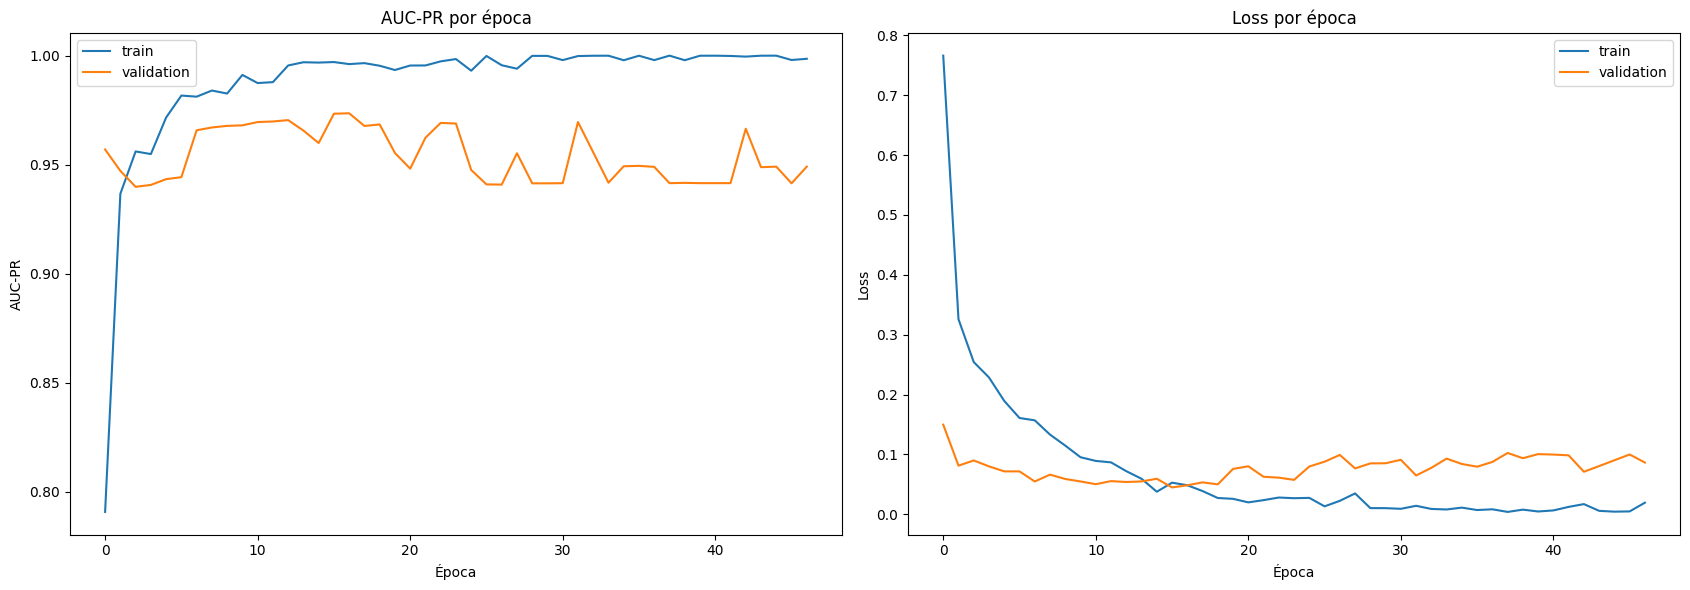

In [337]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].plot(history_lstm.history['auc_pr'], label='train')
axes[0].plot(history_lstm.history['val_auc_pr'], label='validation')
axes[0].set_title('AUC-PR por época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('AUC-PR')
axes[0].legend()

axes[1].plot(history_lstm.history['loss'], label='train')
axes[1].plot(history_lstm.history['val_loss'], label='validation')
axes[1].set_title('Loss por época')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()

Las curvas de **entrenamiento** y **validación** permiten examinar el ajuste; su interpretación depende de la partición y de la ejecución.


### Evaluación del modelo

Se conserva la evaluación original. La prueba debe reservarse para la evaluación final y no utilizarse para elegir hiperparámetros.


In [338]:
train_results = model.evaluate(X_train, Y_train_binary, verbose=0)
test_results = model.evaluate(X_test, Y_test_binary, verbose=0)

train_loss, train_acc, train_auc_roc, train_auc_pr = train_results
test_loss, test_acc, test_auc_roc, test_auc_pr = test_results

print(f"Train -> loss: {train_loss:.4f}  accuracy: {train_acc:.4f}  AUC-ROC: {train_auc_roc:.4f}  AUC-PR: {train_auc_pr:.4f}")
print(f"Test  -> loss: {test_loss:.4f}  accuracy: {test_acc:.4f}  AUC-ROC: {test_auc_roc:.4f}  AUC-PR: {test_auc_pr:.4f}")

E0000 00:00:1790040327.944413    6975 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Train -> loss: 0.0165  accuracy: 0.9946  AUC-ROC: 0.9988  AUC-PR: 0.9962
Test  -> loss: 0.0756  accuracy: 0.9794  AUC-ROC: 0.9831  AUC-PR: 0.9665


Con clases desbalanceadas, evalúa **precisión, exhaustividad, F1 de spam, AUC-PR y matriz de confusión**. No se presupone un porcentaje concreto.


In [339]:
from sklearn.metrics import confusion_matrix, classification_report

yhat_probs = model.predict(X_test, verbose=0)
yhat_classes = (yhat_probs.ravel() > 0.5).astype(int)   # umbral 0.5 sobre la probabilidad sigmoide -> 0/1
true_classes = Y_test_binary                             # ya está en formato binario plano

labels_names = pd.get_dummies(df['Category']).columns.tolist()  # ['ham', 'spam'] en orden alfabético
print(classification_report(true_classes, yhat_classes, target_names=labels_names))

              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       966
        spam       0.90      0.95      0.92       149

    accuracy                           0.98      1115
   macro avg       0.95      0.97      0.96      1115
weighted avg       0.98      0.98      0.98      1115



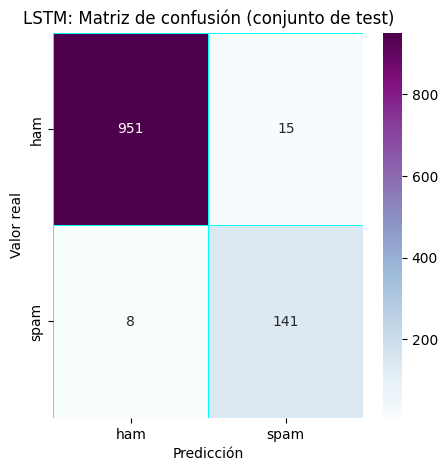

In [340]:
cm = confusion_matrix(true_classes, yhat_classes)

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='g', linewidth=0.7, linecolor='cyan', cmap="BuPu",
            xticklabels=labels_names, yticklabels=labels_names, ax=ax)
plt.title('LSTM: Matriz de confusión (conjunto de test)')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [306]:
model.save('lstm_spam_classifier.keras')
print("Modelo guardado correctamente.")

Modelo guardado correctamente.


### Pruebas con mensajes nuevos

In [307]:
def predecir_mensaje(texto, tokenizer, model, maxlen=MAX_SEQUENCE_LENGTH, labels=('ham', 'spam'), threshold=0.5):
    texto_limpio = cleanText(texto)
    seq = tokenizer.texts_to_sequences([texto_limpio])
    padded = pad_sequences(seq, maxlen=maxlen)
    prob_spam = model.predict(padded, verbose=0)[0][0]   # una sola probabilidad (la de spam), no un vector de 2
    clase = labels[1] if prob_spam > threshold else labels[0]
    return clase, prob_spam

mensajes_prueba = [
    "Congratulations! you have won a $1,000 Walmart gift card. Go to http://bit.ly/123456 to claim now.",
    "thanks for accepting my request to connect",
    "URGENT! Call this number now to claim your free prize before it expires!",
    "Hey, are we still meeting for lunch tomorrow at noon?",
]

for msg in mensajes_prueba:
    clase, prob_spam = predecir_mensaje(msg, tokenizer, model)
    print(f"Mensaje: {msg[:60]}...")
    print(f"  -> Predicción: {clase.upper()}   (probabilidad de spam: {prob_spam:.3f})\n")

Mensaje: Congratulations! you have won a $1,000 Walmart gift card. Go...
  -> Predicción: SPAM   (probabilidad de spam: 1.000)

Mensaje: thanks for accepting my request to connect...
  -> Predicción: HAM   (probabilidad de spam: 0.000)

Mensaje: URGENT! Call this number now to claim your free prize before...
  -> Predicción: SPAM   (probabilidad de spam: 1.000)

Mensaje: Hey, are we still meeting for lunch tomorrow at noon?...
  -> Predicción: HAM   (probabilidad de spam: 0.000)



## Proyecto Integrador de Aprendizaje Automático

### Ejemplo de implementación manual de LSTM y Word2Vec

`````{admonition} Indicaciones generales
:class: tip

- Ambos ejercicios se resuelven con lápiz, papel y una calculadora científica (funciones $\exp$, $\ln$, $\tanh$). No se permite el uso de Python ni de hojas de cálculo.
- Use **cuatro decimales** en todos los cálculos intermedios. Se aceptan diferencias de hasta $\pm 0.002$ respecto a la solución usando Python, debidas al redondeo.
- Use logaritmo natural en todas las pérdidas.
- El superíndice $(k)$ indica el valor de un parámetro después de $k$ actualizaciones de gradiente descendente. Por tanto, $\theta^{(0)}$ son los valores iniciales y $\theta^{(k+1)} = \theta^{(k)} - \eta \, \nabla L(\theta^{(k)})$.
- En cada ejercicio se exige un **número de iteraciones $K^*$** fijado de antemano, junto con un criterio de convergencia explícito. Todos los pesos se actualizan de forma simultánea en cada iteración, de modo que cada peso debe recorrer las $K^*$ iteraciones completas y registrarse en la tabla de trayectorias.
- Los gradientes se promedian sobre los ejemplos de entrenamiento (descenso por lote completo).
`````

### Ejercicio 1: LSTM para análisis de sentimiento

`````{admonition} Enunciado
:class: tip

Se entrena una red **LSTM** con una sola unidad oculta ($\dim h = 1$) y embeddings de dimensión uno para clasificar dos reseñas de dos palabras como positiva (clase 1) o negativa (clase 0). La estructura sigue el ejemplo de BPTT del cuaderno de la red recurrente simple (dos secuencias, una positiva y una negativa, actualización de pesos por gradiente descendente), pero sustituye la celda recurrente por una celda LSTM escalar para que todos los cálculos sean manejables a mano.

Las dos secuencias comparten la última palabra. Por esta razón, el modelo necesita que su **estado interno** transporte información de la primera palabra hasta $n=2$. Una RNN simple también puede hacerlo; la LSTM utiliza una estructura diferente para regular ese flujo.
`````

### Datos

| Secuencia | Texto | Etiqueta $y$ |
|:---:|:---|:---:|
| A | `"great movie"` | 1 (positiva) |
| B | `"awful movie"` | 0 (negativa) |

Embeddings escalares (en este ejercicio no se entrenan):

$$
x(\text{great}) = 1.0, \qquad x(\text{awful}) = -1.0, \qquad x(\text{movie}) = 0.5
$$

Cada secuencia tiene longitud $T=2$, con $x_1$ la primera palabra y $x_2 = 0.5$ la segunda. Estados iniciales: $h_0 = 0$ y $s_0 = 0$.

### Modelo

Para $n = 1, 2$ (con $\sigma(z) = 1/(1+e^{-z})$):

$$
\begin{align*}
f_n &= \sigma(u^f x_n + w^f h_{n-1} + b^f), \\
i_n &= \sigma(u^i x_n + w^i h_{n-1} + b^i), \\
\tilde{s}_n &= \tanh(u^s x_n + w^s h_{n-1} + b^s), \\
o_n &= \sigma(u^o x_n + w^o h_{n-1} + b^o), \\
s_n &= f_n\, s_{n-1} + i_n\, \tilde{s}_n, \\
h_n &= o_n \tanh(s_n).
\end{align*}
$$

Salida binaria a partir del último estado oculto:

$$
z = v\, h_2 + c, \qquad \hat{y} = \sigma(z), \qquad L_{\text{seq}} = -\big[\, y \ln \hat{y} + (1-y)\ln(1-\hat{y}) \,\big]
$$

La pérdida total es el promedio de las dos secuencias: $L = \tfrac{1}{2}(L_A + L_B)$. La secuencia se clasifica como positiva si $\hat y > 0.5$.

```{note}
Una salida softmax de dos clases con logits $(\tilde y_0, \tilde y_1)$ equivale a una sigmoide sobre $z = \tilde y_1 - \tilde y_0$. Por eso el gradiente respecto al logit conserva la forma vista en el cuaderno, $\partial L / \partial z = \hat{y} - y$.
```

### Parámetros iniciales y tasa de aprendizaje

El modelo tiene 14 parámetros escalares:

| Compuerta | $u$ (entrada) | $w$ (recurrente) | $b$ (sesgo) |
|:---|:---:|:---:|:---:|
| Olvido $f$ | $u^f = 0.7$ | $w^f = -0.2$ | $b^f = 0.5$ |
| Entrada $i$ | $u^i = -0.2$ | $w^i = 0.7$ | $b^i = 0.9$ |
| Candidato $\tilde s$ | $u^s = -0.5$ | $w^s = 0.9$ | $b^s = 0.3$ |
| Salida $o$ | $u^o = 0.1$ | $w^o = -0.3$ | $b^o = 0.8$ |

Capa de salida: $v = -1.0$, $c = 0.8$.

Tasa de aprendizaje: $\eta = 3.0$. Este valor es deliberadamente alto para que la convergencia se observe en pocas iteraciones; en una aplicación real se usarían valores mucho menores.

### Retropropagación a través del tiempo (BPTT)

Para cada secuencia, defina $\delta_z = \hat y - y$. Entonces:

$$
\frac{\partial L_{\text{seq}}}{\partial v} = \delta_z\, h_2, \qquad \frac{\partial L_{\text{seq}}}{\partial c} = \delta_z, \qquad dh_2 = \delta_z\, v, \qquad ds_3 \, f_3 \equiv 0
$$

Luego, para $n = 2$ y después para $n = 1$ (hacia atrás en el tiempo):

$$
\begin{align*}
do_n &= dh_n \tanh(s_n), \\
ds_n &= dh_n \, o_n \big(1 - \tanh^2(s_n)\big) + f_{n+1}\, ds_{n+1}, \\
df_n &= ds_n\, s_{n-1}, \qquad di_n = ds_n\, \tilde{s}_n, \qquad d\tilde{s}_n = ds_n\, i_n, \\
\delta^f_n &= df_n\, f_n(1-f_n), \qquad \delta^i_n = di_n\, i_n(1-i_n), \\
\delta^s_n &= d\tilde{s}_n\,(1-\tilde{s}_n^{\,2}), \qquad \delta^o_n = do_n\, o_n(1-o_n), \\
dh_{n-1} &= w^f \delta^f_n + w^i \delta^i_n + w^s \delta^s_n + w^o \delta^o_n .
\end{align*}
$$

Para $n=2$ el término $f_{3}\, ds_{3}$ es cero. Los gradientes de cada parámetro se **acumulan sobre $n=1,2$**. Para cada compuerta $q \in \{f, i, s, o\}$:

$$
\frac{\partial L_{\text{seq}}}{\partial u^q} = \sum_{n=1}^{2} \delta^q_n\, x_n, \qquad
\frac{\partial L_{\text{seq}}}{\partial w^q} = \sum_{n=1}^{2} \delta^q_n\, h_{n-1}, \qquad
\frac{\partial L_{\text{seq}}}{\partial b^q} = \sum_{n=1}^{2} \delta^q_n .
$$

Finalmente, $\nabla L = \tfrac{1}{2}\big(\nabla L_A + \nabla L_B\big)$.

```{note}
Como $h_0 = 0$ y $s_0 = 0$, se cumple que $df_1 = 0$ y que los términos $\delta^q_1\, h_0$ son nulos. Esto reduce el trabajo: los gradientes de $w^q$ provienen solo de $n=2$ y los de $f_1$ no contribuyen.
```

### Tareas

1. **Pasada hacia adelante en $k=0$.** Para las secuencias A y B calcule $f_n, i_n, \tilde s_n, o_n, s_n, h_n$ ($n=1,2$), el logit $z$, la probabilidad $\hat y$, las pérdidas $L_A$, $L_B$ y $L^{(0)}$. Indique qué secuencias quedan mal clasificadas con $\theta^{(0)}$.
2. **BPTT en $k=0$.** Calcule los 14 gradientes de $L_A$ y de $L_B$ y obtenga el gradiente promedio $\nabla L^{(0)}$.
3. **Actualización.** Calcule $\theta^{(1)} = \theta^{(0)} - 3.0\,\nabla L^{(0)}$ para los 14 parámetros.
4. **Iteración completa.** Repita los pasos 1 a 3 hasta obtener $\theta^{(4)}$.
5. **Verificación final.** Con $\theta^{(4)}$ realice una última pasada hacia adelante y calcule $L^{(4)}$, $\hat y_A$ y $\hat y_B$.
6. **Interpretación.** Responda con base en sus cálculos:
    - ¿Cómo evoluciona $L^{(k)}$? ¿Es monótona la trayectoria de cada uno de los 14 pesos?
    - ¿Qué signo tiene $h_2$ en cada secuencia y cómo lo aprovecha $v$ para separar las clases?
    - ¿Por qué el resultado depende de que $s_1$ llegue hasta $n=2$? Identifique el papel de $f_2$.

### Número de iteraciones exigido y criterio de convergencia

```{admonition} Criterio de convergencia
:class: tip

Se declara convergencia en la primera iteración $k$ que satisface **simultáneamente**:

1. $L^{(k)} < 0.20$.
2. $\hat y_A^{(k)} > 0.5$ y $\hat y_B^{(k)} < 0.5$ (ambas secuencias clasificadas correctamente).

Número de iteraciones exigido: **$K^* = 4$ actualizaciones** ($k = 0 \to 4$) para **cada uno de los 14 pesos**. El estudiante debe documentar la tabla de trayectorias completa y demostrar que el criterio no se cumple en $k = 3$ y sí en $k = 4$.
```

### Formato de entrega

**Tabla 1.** Pasada hacia adelante por iteración (una por secuencia y por $k$).

| $k$ | Seq. | $n$ | $x_n$ | $f_n$ | $i_n$ | $\tilde s_n$ | $o_n$ | $s_n$ | $h_n$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| | | | | | | | | | |

**Tabla 2.** Resumen de pérdida y clasificación.

| $k$ | $z_A$ | $z_B$ | $\hat y_A$ | $\hat y_B$ | $L_A$ | $L_B$ | $L^{(k)}$ | ¿A correcta? | ¿B correcta? |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 0 | | | | | | | | | |
| 1 | | | | | | | | | |
| 2 | | | | | | | | | |
| 3 | | | | | | | | | |
| 4 | | | | | | | | | |

**Tabla 3.** Trayectoria de los 14 pesos.

| Parámetro | $k=0$ | $k=1$ | $k=2$ | $k=3$ | $k=4$ |
|:---|:---:|:---:|:---:|:---:|:---:|
| $u^f$ | 0.7 | | | | |
| $w^f$ | -0.2 | | | | |
| $b^f$ | 0.5 | | | | |
| $u^i$ | -0.2 | | | | |
| $w^i$ | 0.7 | | | | |
| $b^i$ | 0.9 | | | | |
| $u^s$ | -0.5 | | | | |
| $w^s$ | 0.9 | | | | |
| $b^s$ | 0.3 | | | | |
| $u^o$ | 0.1 | | | | |
| $w^o$ | -0.3 | | | | |
| $b^o$ | 0.8 | | | | |
| $v$ | -1.0 | | | | |
| $c$ | 0.8 | | | | |

### Ejercicio 2: Embeddings tipo word2vec con retropropagación

`````{admonition} Enunciado
:class: tip

Se entrena una red de una capa oculta lineal con salida softmax (arquitectura **skip-gram** de word2vec) sobre un corpus de dos textos muy cortos. Dada una palabra central, la red predice una palabra de su contexto. Al finalizar, las **filas de $W_1$ son los embeddings** de las palabras. La hipótesis distribucional que sustenta word2vec predice que dos palabras que aparecen en contextos idénticos deben terminar con embeddings similares; este es el resultado que se verificará a mano.
`````

### Corpus y pares de entrenamiento

Textos: `"cat sleeps"` y `"dog sleeps"`. Vocabulario con $V=3$ palabras, indexadas como: cat (1), dog (2), sleeps (3). Dimensión del embedding: $N = 2$.

Con ventana de contexto de tamaño 1 (en ambos sentidos), los pares (palabra central $\to$ contexto) son:

| Par | Central | Contexto |
|:---:|:---:|:---:|
| 1 | cat | sleeps |
| 2 | sleeps | cat |
| 3 | dog | sleeps |
| 4 | sleeps | dog |

El número de pares es $M = 4$.

### Modelo

Sea $x_c \in \mathbb{R}^{3}$ el vector one-hot de la palabra central $c$. La red calcula:

$$
h = x_c^\top W_1 \in \mathbb{R}^{1 \times 2}, \qquad u = h\, W_2 \in \mathbb{R}^{1 \times 3}, \qquad \hat{y} = \text{softmax}(u)
$$

con $W_1 \in \mathbb{R}^{3 \times 2}$ (la fila $c$ es el embedding de la palabra $c$, de modo que $h$ es simplemente esa fila) y $W_2 \in \mathbb{R}^{2 \times 3}$ (la columna $j$ es el vector de contexto de la palabra $j$). La pérdida sobre el lote completo es:

$$
L = \frac{1}{M} \sum_{(c,t)} -\ln \hat{y}_t^{(c)}
$$

donde $t$ es la palabra de contexto del par $(c,t)$.

### Parámetros iniciales y tasa de aprendizaje

$$
W_1^{(0)} = \begin{bmatrix} 0.2 & -0.3 \\ -0.1 & 0.4 \\ 0.3 & 0.1 \end{bmatrix}
\begin{matrix} \text{cat} \\ \text{dog} \\ \text{sleeps} \end{matrix}, \qquad
W_2^{(0)} = \begin{bmatrix} 0.1 & -0.2 & 0.3 \\ 0.2 & 0.1 & -0.1 \end{bmatrix}
$$

Tasa de aprendizaje: $\eta = 4.0$ (alta por motivos didácticos, para observar la convergencia en pocas iteraciones).

### Gradientes

Para cada par $(c,t)$ defina el vector de error $e = \hat{y} - t_{\text{onehot}} \in \mathbb{R}^{3}$ (se resta 1 únicamente en la posición de la palabra de contexto $t$). Entonces:

$$
\frac{\partial L}{\partial W_2} = \frac{1}{M} \sum_{(c,t)} h^\top e, \qquad
\frac{\partial L}{\partial W_1}\Big|_{\text{fila } c} = \frac{1}{M} \sum_{(c,t)} \big( W_2\, e^\top \big)^\top
$$

En la segunda expresión, la suma se hace solo sobre los pares cuya palabra central es $c$. Las filas de $W_1$ que no aparecen como palabra central en un par tienen gradiente nulo por ese par. **Importante:** el gradiente de $W_1$ debe calcularse con el $W_2$ de la iteración actual (actualización simultánea de $W_1$ y $W_2$).

### Tareas

1. **Cota inferior de la pérdida.** Sin entrenar, determine la cota inferior $L_{\inf}$ para las distribuciones empíricas. Con parámetros finitos el softmax no alcanza probabilidades exactamente iguales a cero o uno; la cota es un **ínfimo**. Sugerencia: las palabras cat y dog tienen un único contexto posible, mientras que sleeps tiene dos contextos igualmente frecuentes; calcule la entropía de la distribución empírica de contextos de cada palabra central, ponderada por su frecuencia como palabra central.
2. **Pasada hacia adelante en $k=0$.** Para los cuatro pares calcule $h$, $u$, $\hat y$ y la pérdida por par; obtenga $L^{(0)}$.
3. **Retropropagación en $k=0$.** Calcule $e$ y $W_2 e^\top$ de cada par; obtenga $\partial L/\partial W_1$ y $\partial L/\partial W_2$.
4. **Actualización.** Calcule $W_1^{(1)}$ y $W_2^{(1)}$.
5. **Iteración completa.** Repita los pasos 2 a 4 hasta obtener $W_1^{(6)}$ y $W_2^{(6)}$.
6. **Verificación de los embeddings.** Con los parámetros finales:
    - Calcule la similitud coseno entre los embeddings de cat y dog en cada $k$.
    - Calcule $\hat y$ para los tres valores de palabra central y compruebe que $P(\text{sleeps} \mid \text{cat})$ y $P(\text{sleeps} \mid \text{dog})$ son cercanas a 1 y que $P(\text{cat} \mid \text{sleeps}) \approx P(\text{dog} \mid \text{sleeps}) \approx 0.5$.
7. **Interpretación.** Responda con base en sus cálculos:
    - ¿Cómo evolucionan los embeddings de cat y dog en esta ejecución y qué límites tiene interpretar su cercanía?
    - ¿Por qué $L_{\inf} > 0$, y por qué el gradiente nunca se anula exactamente en los pesos de cat y dog?
    - En un vocabulario real ($V \approx 10^5$), ¿qué paso de esta iteración resulta inviable y qué alternativa usa word2vec?

### Número de iteraciones exigido y criterio de convergencia

```{admonition} Criterio de convergencia
:class: tip

Sea $\Delta_{ij}^{(k)} = W_{1,ij}^{(k)} - W_{1,ij}^{(k-1)}$ la variación del peso $(i,j)$ de $W_1$ en la iteración $k \geq 1$. Para este experimento se fija una tolerancia operativa; un paso pequeño aislado no demuestra convergencia matemática:

- **Criterio por peso.** Se registra la primera iteración $k^*_{ij}$ tal que $|\Delta_{ij}^{(k)}| < 0.06$.
- **Criterio global.** $L^{(k)} - L_{\inf} < 0.02$.

El estudiante debe reportar $k^*_{ij}$ para cada uno de los **seis pesos de $W_1$** (cat, dog y sleeps, cada uno con dos componentes). El número de iteraciones exigido es $K^* = \max_{ij} k^*_{ij}$, es decir, **$K^* = 6$** iteraciones, en las que todos los pesos de $W_1$ y de $W_2$ se actualizan simultáneamente.
```

### Formato de entrega

**Tabla 1.** Cálculo por iteración (repetir para cada $k$).

| Par | $h$ | $u$ | $\hat{y}$ | $-\ln \hat{y}_t$ | $e$ | $W_2\, e^\top$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| cat $\to$ sleeps | | | | | | |
| sleeps $\to$ cat | | | | | | |
| dog $\to$ sleeps | | | | | | |
| sleeps $\to$ dog | | | | | | |

**Tabla 2.** Trayectoria de la pérdida y de los embeddings.

| $k$ | $L^{(k)}$ | $L^{(k)} - L_{\inf}$ | $W_{1,11}$ | $W_{1,12}$ | $W_{1,21}$ | $W_{1,22}$ | $W_{1,31}$ | $W_{1,32}$ | $\cos(\text{cat},\text{dog})$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 0 | | | 0.2 | -0.3 | -0.1 | 0.4 | 0.3 | 0.1 | |
| 1 | | | | | | | | | |
| 2 | | | | | | | | | |
| 3 | | | | | | | | | |
| 4 | | | | | | | | | |
| 5 | | | | | | | | | |
| 6 | | | | | | | | | |

**Tabla 3.** Iteración de convergencia por peso.

| Peso de $W_1$ | cat 1 | cat 2 | dog 1 | dog 2 | sleeps 1 | sleeps 2 |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| $k^*_{ij}$ | | | | | | |

## Proyecto integrador original

Se conservan las **indicaciones, tareas y proyectos** presentes en el archivo de origen. Aunque la aplicación principal de este cuaderno es NLP, el proyecto integrador original también incluye un bloque de **segmentación de imágenes**, junto con un bloque de NLP y actividades de MLOps. Se mantienen para no perder las instrucciones originales.

```{note}
El ejemplo de mensajes SMS usa la base enlazada al inicio. Los proyectos que indican otras bases conservan sus propios enlaces y requisitos originales.
```


### Segmentación de instancias celulares y clasificación de texto

### Resumen del proyecto

Este proyecto se plantea como una **investigación empírica completa**, no como una colección de modelos entrenados. Se estudian dos dominios (imágenes biomédicas y texto) con un mismo estándar metodológico:

1. Un **protocolo experimental pre-registrado** antes de ejecutar experimentos.
2. **Auditoría de datos** (fugas, duplicados, ruido de etiquetas, sesgos) previa al modelado.
3. Comparación de modelos con **presupuesto de cómputo equitativo**, múltiples semillas e **inferencia estadística** (intervalos de confianza, pruebas pareadas, corrección por comparaciones múltiples, tamaños de efecto).
4. **Ablaciones** que aíslan la contribución de cada decisión de diseño.
5. Evaluación de **robustez, calibración, incertidumbre, explicabilidad y equidad**.
6. **Costo–beneficio**: eficiencia computacional, latencia y huella de carbono.
7. **Despliegue reproducible** con pruebas automáticas, versionado y monitoreo con detección de deriva simulada.

El producto final es un **Jupyter Book con estructura de artículo científico** acompañado de un paquete de código reproducible con un solo comando.

### Objetivos, preguntas de investigación e hipótesis

#### Objetivo general

Diseñar, implementar y comparar con validez estadística modelos de *deep learning* y clásicos para (i) segmentación de instancias celulares y (ii) clasificación de texto, cuantificando no solo **qué tan bien** funcionan, sino **cuándo, por qué, con qué incertidumbre, a qué costo y con qué riesgos** fallan.

#### Objetivos específicos

- **O1.** Auditar y caracterizar los datos identificando fuentes de sesgo, fuga de información y ruido de anotación.
- **O2.** Implementar desde cero al menos un modelo por dominio (con funciones de pérdida y métricas propias) y configurar rigurosamente los demás.
- **O3.** Comparar modelos bajo un protocolo controlado y reportar diferencias con inferencia estadística, no con rankings de una sola ejecución.
- **O4.** Identificar mediante ablaciones qué componentes (resolución, *augmentation*, pérdida, preentrenamiento, preprocesamiento de texto) explican el rendimiento.
- **O5.** Evaluar robustez ante cambio de distribución, calibración de probabilidades, incertidumbre y equidad.
- **O6.** Empaquetar y desplegar el mejor modelo de cada dominio con pruebas, CI/CD y un experimento de detección de deriva.

#### Preguntas de investigación

| ID | Pregunta | Dominio |
|----|----------|---------|
| **RQ1** | ¿Cómo varía el desempeño de los cinco paradigmas según tipo celular, densidad de células y tamaño de objeto, y qué diferencias son estadística **y** prácticamente relevantes? | Imágenes |
| **RQ2** | ¿Cuál es la contribución marginal de resolución, *augmentation*, función de pérdida y preentrenamiento? ¿Cómo escala el rendimiento con la fracción de datos de entrenamiento? | Imágenes |
| **RQ3** | ¿Son las métricas en píxeles (Dice, AUC, *balanced accuracy*) consistentes con las métricas por instancia (AP, PQ)? ¿Cuándo se contradicen? | Imágenes |
| **RQ4** | ¿Qué tan robustos y calibrados son los modelos bajo cambio de dominio (*leave-one-cell-type-out*) y perturbaciones de imagen? | Imágenes |
| **RQ5** | Controlando presupuesto de optimización de hiperparámetros y varianza entre semillas, ¿justifica el costo de un *transformer* su ganancia frente a *baselines* clásicos? | NLP |
| **RQ6** | ¿Qué proporción del rendimiento se debe a atajos léxicos o a ruido de etiquetas, y cómo cambia bajo perturbaciones controladas? | NLP |
| **RQ7** | ¿Están calibradas las probabilidades y existen disparidades de desempeño entre subgrupos? | NLP |
| **RQ8** | ¿Cómo se degrada el rendimiento ante deriva de datos y con qué rapidez y poder la detecta el sistema de monitoreo? | MLOps |

#### Hipótesis falsables (ejemplos que deben refinar y pre-registrar)

- **H1.** Los modelos con preentrenamiento superan a U-Net++ entrenada desde cero cuando se usa ≤ 25 % de los datos, y la brecha se reduce con el 100 %. *Se refuta si el IC 95 % de la diferencia en AP incluye 0 al 25 %.*
- **H2.** AUC y *balanced accuracy* en píxeles saturan (> 0.95) sin discriminar entre modelos, mientras que AP@[0.5:0.95] sí los discrimina. *Se refuta si la correlación de rangos (Spearman) entre ambos órdenes es > 0.9.*
- **H3.** El *ranking* global de modelos cambia al estratificar por tipo celular (paradoja de Simpson). *Se refuta si el orden es idéntico en los tres tipos.*
- **H4.** La diferencia de F1 entre el mejor *transformer* y TF-IDF + XGBoost **no** es estadísticamente significativa tras corregir por comparaciones múltiples y varianza entre semillas. *Hipótesis nula a contrastar explícitamente.*
- **H5.** El *fine-tuning* empeora la calibración (ECE) y el *temperature scaling* la recupera sin alterar la exactitud.

> **Valor de resultados negativos.** Refutar una hipótesis con evidencia sólida es un resultado tan evaluable como confirmarla. Lo que se penaliza es no haberla declarado antes.

### Datos y contexto

#### Segmentación de imágenes
- [Sartorius - Cell Instance Segmentation](https://www.kaggle.com/competitions/sartorius-cell-instance-segmentation/overview). Imágenes de microscopía de contraste de fase con máscaras en RLE. Conjunto con **tres tipos celulares** (SH-SY5Y, astrocitos, *cort*) y metadatos de placa/muestra. Incluye imágenes adicionales sin anotar que pueden usarse en extensiones semi-supervisadas.
- Literatura de contexto: conjunto LIVECell (Edlund et al., 2021).

#### NLP
- [Jarvis Calling Hiring Contest](https://www.kaggle.com/competitions/jarvis-calling-hiring-contest/overview). Textos etiquetados en contexto de reclutamiento.
- Guía de EDA de texto: [Complete Guide to EDA on Text Data](https://www.kaggle.com/code/harshsingh2209/complete-guide-to-eda-on-text-data).
- Al tratarse de un contexto de **selección de personal**, el análisis de equidad y de riesgo es obligatorio (sección «Equidad y riesgo (contexto de reclutamiento)»).

#### Ficha de datos obligatoria (*datasheet*)

Antes de modelar, cada dataset debe documentarse con: origen y licencia/términos de uso, proceso de recolección y anotación, composición (clases, subgrupos, metadatos), usos previstos y no previstos, limitaciones conocidas y riesgos de privacidad. **Verifique el esquema real de los archivos** (columnas, tamaños, canales) y registre las discrepancias con lo supuesto en este enunciado.

### Protocolo experimental transversal (pre-registro)

Esta sección se **completa y se congela (*commit* con etiqueta `prereg`) antes de entrenar cualquier modelo final**. Cualquier desviación posterior se declara como tal en el reporte.

#### Tabla de pre-registro

| Elemento | Qué debe declararse |
|----------|---------------------|
| Hipótesis | H1–H5 refinadas con criterio de refutación numérico |
| Métrica primaria | Una por dominio (imágenes: AP@[0.5:0.95] estilo Sartorius; NLP: F1 macro, salvo que el EDA justifique otra) |
| Métricas secundarias | Lista cerrada de antemano |
| Unidad de análisis | Imagen (segmentación) o ejemplo/*fold* (NLP) |
| Diseño de particiones | Ver «Particiones y prevención de fuga de información» |
| Pruebas estadísticas | Ver «Plan estadístico», con α = 0.05 y corrección de Holm |
| Efecto mínimo relevante (δ) | Diferencia mínima que consideraría útil en la práctica y su justificación |
| Semillas | ≥ 5 para modelos ligeros, ≥ 3 para modelos pesados |
| Presupuesto | Horas-GPU y número de *trials* de HPO **idénticos** entre modelos comparables |
| Criterios de parada | *Early stopping* sobre validación, con paciencia declarada |

#### Particiones y prevención de fuga de información

- **Segmentación:** separar **por imagen y por grupo experimental** (`sample_id`/placa/fecha), nunca por instancia. Usar `StratifiedGroupKFold` estratificando por tipo celular. Las imágenes de una misma placa comparten condiciones técnicas; repartirlas entre *train* y *test* infla el rendimiento.
- **NLP:** partición estratificada; antes de dividir, eliminar duplicados exactos y **casi-duplicados** (MinHash/LSH) y verificar que no crucen particiones. Si hay estructura temporal o por autor, usar partición temporal/por grupo.
- **Test sellado:** 15 % que se evalúa **una sola vez por modelo final**. Todo ajuste (incluido el de umbrales y post-procesamiento) usa solo validación.
- **Transformaciones ajustadas solo con *train*:** TF-IDF, vocabulario, *tokenizer*, Word2Vec/FastText entrenados desde cero, estadísticos de normalización.
- **Esquema de validación:**
  - 70/15/15 (*train/val/test*) agrupado.
  - **Validación cruzada 5-fold** de la mejor configuración de cada modelo para estimar varianza.
  - **Validación anidada completa** para modelos ligeros (XGBoost, FastText, CNN-1D, BiLSTM). Para modelos pesados (Mask R-CNN, Hover-Net, Cellpose, SAM, *transformers*) se permite HPO sobre un único *split* de validación y 5-fold con configuración fija, **declarando el sesgo optimista** que esto introduce.

#### Reproducibilidad y seguimiento

Semillas fijadas (Python, NumPy, TF/PyTorch), operaciones deterministas cuando sea posible, versiones bloqueadas (`requirements.lock`), configuración en archivos (YAML/Hydra) y registro de experimentos (MLflow o Weights & Biases) con: *commit*, configuración, semilla, métricas, artefactos y tiempo/energía consumidos. Los datos se versionan con DVC (o equivalente) y se registran sus *hashes*.

#### Plan estadístico

- **Intervalos de confianza** bootstrap (percentil o BCa, ≥ 10 000 remuestreos) **sobre unidades de análisis**, no sobre píxeles.
- **Comparación de dos modelos:** prueba de Wilcoxon de rangos con signo pareada (segmentación, por imagen); McNemar exacto o *t* remuestreada corregida de Nadeau–Bengio / 5×2cv de Dietterich (NLP).
- **Comparación de ≥ 3 modelos:** Friedman + *post hoc* por pares con **corrección de Holm**; diagrama de diferencia crítica.
- **Tamaños de efecto:** *d* de Cohen pareado y delta de Cliff, con interpretación práctica respecto a δ.
- **Estructura jerárquica:** verificar, con un modelo mixto (`statsmodels.mixedlm`, intercepto aleatorio por `sample_id`), que las conclusiones no se deben a la correlación intra-placa.
- **Extensión bayesiana (opcional):** prueba de rangos con signo bayesiana con región de equivalencia práctica (ROPE) (Benavoli et al., 2017).
- **Varianza entre semillas:** reportar media ± DE y distinguir explícitamente varianza por semilla, por *split* y por datos (Bouthillier et al., 2021).

#### Reglas de reporte

- Toda cifra se reporta como **media [IC 95 %]**; nunca un valor único sin incertidumbre.
- Figuras cualitativas: muestra **aleatoria con semilla fija** + los **5 mejores y 5 peores** casos por métrica. Queda prohibido seleccionar solo ejemplos favorables.
- Toda métrica se acompaña de su definición exacta y de la implementación utilizada.

### Fundamentos teóricos obligatorios

Resuelva analíticamente (en LaTeX, en el Jupyter Book) y **verifique numéricamente** cada punto en una celda de código.

1. **Relación Dice–IoU.** Demuestre que $D = \dfrac{2J}{1+J}$ para un mismo par (predicción, referencia), que la relación es monótona y que, por tanto, *rankings* por Dice e IoU coinciden por imagen pero **no necesariamente al promediar** sobre imágenes. Construya un contraejemplo numérico.
2. **Gradiente de la pérdida Dice suave.** Deduzca $\partial \mathcal{L}_{Dice}/\partial p_i$ para $\mathcal{L}_{Dice}=1-\frac{2\sum p_i g_i+\epsilon}{\sum p_i+\sum g_i+\epsilon}$ y discuta su comportamiento cuando la clase foreground ocupa una fracción mínima de la imagen. Compárela con la entropía cruzada y con la pérdida focal.
3. **Desbalance y métricas de píxel.** Sea $\pi$ la proporción de píxeles de célula. Muestre cómo varían la exactitud, la *balanced accuracy* y el AUC-ROC de un clasificador trivial o casi trivial cuando $\pi \to 0$, y por qué la curva Precision–Recall es más informativa en ese régimen.
4. **Sesgo de la validación cruzada.** Discuta por qué reportar el mejor resultado de una búsqueda de hiperparámetros sobre la misma validación es optimista, y cómo la validación anidada lo corrige. Estime empíricamente el sesgo en un modelo ligero.
5. **Calibración.** Defina ECE y puntaje de Brier, y demuestre que la temperatura $T$ en $\operatorname{softmax}(z/T)$ no altera el $\arg\max$ (la exactitud no cambia) pero sí la NLL.
6. **Complejidad.** Para U-Net++, BiLSTM y una capa de auto-atención, derive órdenes de complejidad en tiempo y memoria respecto al tamaño de entrada y contraste con mediciones empíricas.

### Utilidades de código reutilizables

Las siguientes celdas incluyen implementaciones **verificadas con pruebas sintéticas** de las piezas metodológicas centrales. Deben trasladarse a un paquete `src/` con pruebas unitarias (`pytest`). Complete, extienda y **critique** estas implementaciones: por ejemplo, documente sus supuestos (objetos no solapados, convención de RLE) y casos borde.

```python
# ---------- Configuración, semillas y entorno ----------
import os, platform, random
from dataclasses import dataclass
from pathlib import Path
from importlib import metadata
import numpy as np
import pandas as pd

@dataclass(frozen=True)
class ExperimentConfig:
    seed: int = 42
    seeds_eval: tuple = (0, 1, 2, 3, 4)
    alpha: float = 0.05
    n_boot: int = 10_000
    img_size: int = 512
    val_frac: float = 0.15
    test_frac: float = 0.15
    k_folds: int = 5
    data_dir: Path = Path("data")
    out_dir: Path = Path("outputs")

CFG = ExperimentConfig()

def set_global_seed(seed: int, deterministic: bool = True) -> None:
    """Fija semillas en Python, NumPy, TensorFlow y PyTorch (si están instalados)."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)
        if deterministic:
            tf.config.experimental.enable_op_determinism()
    except ImportError:
        pass
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        if deterministic:
            torch.use_deterministic_algorithms(True, warn_only=True)
            torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

def environment_report(pkgs=("numpy", "pandas", "scipy", "scikit-learn", "tensorflow", "torch", "optuna")) -> dict:
    """Versiones de software para el reporte de reproducibilidad."""
    rep = {"python": platform.python_version(), "platform": platform.platform()}
    for p in pkgs:
        try:
            rep[p] = metadata.version(p)
        except metadata.PackageNotFoundError:
            rep[p] = None
    return rep

set_global_seed(CFG.seed)
print(environment_report())
```

```python
# ---------- RLE y mapas de etiquetas ----------
# Convención Sartorius: RLE 1-indexado "inicio longitud ...". Verifique VISUALMENTE con superposiciones
# que el orden de aplanado (reshape) es correcto para sus datos antes de continuar.

def rle_decode(rle: str, shape: tuple) -> np.ndarray:
    """RLE -> máscara binaria de forma (alto, ancho)."""
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        s = np.asarray(rle.split(), dtype=np.int64)
        starts, lengths = s[0::2] - 1, s[1::2]
        for a, l in zip(starts, lengths):
            mask[a:a + l] = 1
    return mask.reshape(shape)

def rle_encode(mask: np.ndarray) -> str:
    """Máscara binaria -> RLE 1-indexado."""
    pixels = np.concatenate([[0], mask.flatten(), [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))

def instances_to_label_map(rles, shape) -> np.ndarray:
    """Lista de RLE -> mapa de etiquetas (0 = fondo). Solapes: prevalece la primera instancia."""
    lbl = np.zeros(shape, dtype=np.int32)
    for i, r in enumerate(rles, start=1):
        m = rle_decode(r, shape).astype(bool)
        lbl[m & (lbl == 0)] = i
    return lbl
```

```python
# ---------- Métricas de segmentación (píxel, borde e instancia) ----------
from scipy import ndimage as ndi

def dice_iou(pred, gt, eps: float = 1e-7):
    p, g = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    return (2 * inter + eps) / (p.sum() + g.sum() + eps), (inter + eps) / (union + eps)

def pixel_confusion_metrics(pred, gt) -> dict:
    p, g = pred.astype(bool), gt.astype(bool)
    tp = np.logical_and(p, g).sum(); fp = np.logical_and(p, ~g).sum()
    fn = np.logical_and(~p, g).sum(); tn = np.logical_and(~p, ~g).sum()
    recall = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(precision=tp / max(tp + fp, 1), recall=recall, specificity=spec,
                balanced_accuracy=0.5 * (recall + spec))

def hausdorff95(a, b) -> float:
    """Distancia de Hausdorff al percentil 95 entre contornos (en píxeles)."""
    a, b = a.astype(bool), b.astype(bool)
    if not a.any() and not b.any():
        return 0.0
    if not a.any() or not b.any():
        return np.inf
    sa, sb = a ^ ndi.binary_erosion(a), b ^ ndi.binary_erosion(b)
    da = ndi.distance_transform_edt(~sb)[sa]
    db = ndi.distance_transform_edt(~sa)[sb]
    return float(np.percentile(np.concatenate([da, db]), 95))

def _relabel(lbl):
    u, inv = np.unique(lbl, return_inverse=True)
    inv = inv.reshape(lbl.shape)
    return inv if u[0] == 0 else inv + 1

def instance_iou_matrix(gt_lbl, pr_lbl) -> np.ndarray:
    """Matriz IoU (n_gt x n_pred) entre mapas de etiquetas."""
    gt_lbl, pr_lbl = _relabel(gt_lbl), _relabel(pr_lbl)
    n_gt, n_pr = gt_lbl.max(), pr_lbl.max()
    idx = gt_lbl.ravel().astype(np.int64) * (n_pr + 1) + pr_lbl.ravel()
    inter = np.bincount(idx, minlength=(n_gt + 1) * (n_pr + 1)).reshape(n_gt + 1, n_pr + 1)
    a_gt, a_pr = inter.sum(1), inter.sum(0)
    union = a_gt[:, None] + a_pr[None, :] - inter
    return (inter / np.maximum(union, 1))[1:, 1:]

THRESHOLDS = np.arange(0.5, 1.0, 0.05)

def sartorius_score(gt_lbl, pr_lbl, thresholds=THRESHOLDS) -> float:
    """Media sobre umbrales de IoU de TP/(TP+FP+FN). Con instancias disjuntas y t>=0.5 el emparejamiento es único."""
    iou = instance_iou_matrix(gt_lbl, pr_lbl)
    n_gt, n_pr = iou.shape
    scores = []
    for t in thresholds:
        tp = int((iou > t).sum()); fp = n_pr - tp; fn = n_gt - tp
        d = tp + fp + fn
        scores.append(tp / d if d else 1.0)
    return float(np.mean(scores))

def panoptic_quality(gt_lbl, pr_lbl):
    """PQ = SQ * RQ (Kirillov et al., 2019). Devuelve (PQ, SQ, RQ)."""
    iou = instance_iou_matrix(gt_lbl, pr_lbl)
    n_gt, n_pr = iou.shape
    matched = iou > 0.5
    tp = int(matched.sum()); fp = n_pr - tp; fn = n_gt - tp
    if tp + fp + fn == 0:
        return 1.0, 1.0, 1.0
    sq = float(iou[matched].mean()) if tp else 0.0
    rq = tp / (tp + 0.5 * fp + 0.5 * fn)
    return sq * rq, sq, rq
```

```python
# ---------- Inferencia estadística ----------
from itertools import combinations
from scipy import stats

def bootstrap_ci(x, stat=np.mean, n_boot: int = 10_000, alpha: float = 0.05, seed: int = 0):
    """IC bootstrap percentil sobre unidades de análisis. Devuelve (estimador, lo, hi)."""
    x = np.asarray(x, float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    boots = stat(x[idx], axis=1)
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(stat(x)), float(lo), float(hi)

def cliffs_delta(a, b) -> float:
    a, b = np.asarray(a), np.asarray(b)
    return float(((a[:, None] > b[None, :]).sum() - (a[:, None] < b[None, :]).sum()) / (len(a) * len(b)))

def holm_adjust(pvals) -> np.ndarray:
    p = np.asarray(pvals, float); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def compare_models(scores: pd.DataFrame, alpha: float = 0.05) -> dict:
    """scores: filas = unidades pareadas (imágenes/folds), columnas = modelos (>= 3).
    Friedman + Wilcoxon por pares con corrección de Holm + tamaños de efecto."""
    models = list(scores.columns)
    fr = stats.friedmanchisquare(*[scores[m] for m in models])
    rows = []
    for a, b in combinations(models, 2):
        d = scores[a] - scores[b]
        try:
            p = stats.wilcoxon(scores[a], scores[b]).pvalue
        except ValueError:          # todas las diferencias son cero
            p = 1.0
        sd = d.std(ddof=1)
        rows.append(dict(A=a, B=b, mean_diff=d.mean(), cohen_dz=(d.mean() / sd) if sd > 0 else 0.0,
                         cliffs_delta=cliffs_delta(scores[a], scores[b]), p_raw=p))
    out = pd.DataFrame(rows)
    out["p_holm"] = holm_adjust(out["p_raw"]); out["reject"] = out["p_holm"] < alpha
    ranks = scores.rank(axis=1, ascending=False).mean().sort_values()
    return {"friedman_stat": float(fr.statistic), "friedman_p": float(fr.pvalue),
            "mean_ranks": ranks, "pairwise": out}

def corrected_resampled_ttest(diffs, n_train: int, n_test: int):
    """t remuestreada corregida (Nadeau & Bengio, 2003) sobre diferencias por repetición de CV."""
    d = np.asarray(diffs, float); k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return float(t), float(2 * stats.t.sf(abs(t), k - 1))

def mcnemar_exact(y_true, pred_a, pred_b) -> float:
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    b01, b10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    n = b01 + b10
    return 1.0 if n == 0 else float(stats.binomtest(b01, n, 0.5).pvalue)
```

```python
# ---------- Calibración y deriva de datos ----------
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def expected_calibration_error(probs, y, n_bins: int = 15) -> float:
    probs, y = np.asarray(probs), np.asarray(y)
    conf, acc = probs.max(1), (probs.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(ece)

def fit_temperature(logits, y) -> float:
    """Temperature scaling (Guo et al., 2017): minimiza la NLL en validación."""
    from scipy.optimize import minimize_scalar
    logits, y = np.asarray(logits), np.asarray(y)
    def nll(T):
        p = softmax(logits / T)
        return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
    return float(minimize_scalar(nll, bounds=(0.05, 10), method="bounded").x)

def psi(ref, cur, bins: int = 10, eps: float = 1e-6) -> float:
    """Population Stability Index con cortes por cuantiles de la referencia."""
    ref, cur = np.asarray(ref, float), np.asarray(cur, float)
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), eps, None)
    c = np.clip(np.histogram(cur, edges)[0] / len(cur), eps, None)
    return float(np.sum((c - r) * np.log(c / r)))

def drift_report(ref, cur) -> dict:
    ks = stats.ks_2samp(ref, cur)
    return dict(psi=psi(ref, cur), ks_stat=float(ks.statistic), ks_p=float(ks.pvalue))
```

```python
# ---------- Esqueleto de HPO (presupuesto equitativo entre modelos) ----------
# Espacio BiLSTM del enunciado: el producto cartesiano completo es inviable -> búsqueda bayesiana con poda.
GRID_SIZE = 3 * 2 * 2 * 3 * 2 * 2 * 2 * 2   # units, layers, dropout, lr, batch, seq_len, max_epochs, emb_dim
print("Tamaño de la rejilla completa del BiLSTM:", GRID_SIZE, "configuraciones")

def suggest_bilstm_space(trial) -> dict:
    return dict(
        lstm_units=trial.suggest_categorical("lstm_units", [32, 64, 128]),
        num_lstm_layers=trial.suggest_categorical("num_lstm_layers", [1, 2]),
        dropout_rate=trial.suggest_categorical("dropout_rate", [0.3, 0.5]),
        learning_rate=trial.suggest_categorical("learning_rate", [0.0005, 0.001, 0.003]),
        batch_size=trial.suggest_categorical("batch_size", [32, 64]),
        sequence_length=trial.suggest_categorical("sequence_length", [50, 100]),
        max_epochs=trial.suggest_categorical("max_epochs", [20, 50]),   # con early stopping
        embedding_dim=trial.suggest_categorical("embedding_dim", [100, 200]),
    )

def run_study(objective, n_trials: int = 30, seed: int = 0, direction: str = "maximize"):
    """Mismo n_trials y misma semilla del sampler para todos los modelos comparables."""
    import optuna
    sampler = optuna.samplers.TPESampler(seed=seed)
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=3)
    study = optuna.create_study(direction=direction, sampler=sampler, pruner=pruner)
    study.optimize(objective, n_trials=n_trials)
    return study   # luego: optuna.importance.get_param_importances(study)  (análisis de sensibilidad)
```

```python
# ---------- Verificación (pruebas sintéticas) ----------
rng = np.random.default_rng(0)

# RLE ida y vuelta
m = np.zeros((40, 50), np.uint8); m[5:15, 10:30] = 1; m[25:35, 5:20] = 1
assert (rle_decode(rle_encode(m), m.shape) == m).all()

# Métricas de instancia
gt = np.zeros((64, 64), np.int32); gt[5:25, 5:25] = 1; gt[35:60, 35:60] = 2
assert abs(sartorius_score(gt, gt) - 1.0) < 1e-12
assert sartorius_score(gt, np.zeros_like(gt)) == 0.0
pq, sq, rq = panoptic_quality(gt, gt); assert abs(pq - 1) < 1e-12

# Relación Dice-IoU: D = 2J / (1 + J)
a = rng.random((64, 64)) > 0.5; b = rng.random((64, 64)) > 0.5
d, j = dice_iou(a, b); assert abs(d - 2 * j / (1 + j)) < 1e-6

# Hausdorff95: cuadrados desplazados 3 px
s1 = np.zeros((60, 60), bool); s1[10:40, 10:40] = True
s2 = np.zeros((60, 60), bool); s2[10:40, 13:43] = True
assert 2.0 <= hausdorff95(s1, s2) <= 4.0

# Comparación estadística: M2 es mejor que M1 y M3 ~ M1
n = 80
base = rng.normal(0.6, 0.05, n)
sc = pd.DataFrame({"M1": base, "M2": base + 0.05 + rng.normal(0, 0.01, n), "M3": base + rng.normal(0, 0.01, n)})
res = compare_models(sc)
assert res["friedman_p"] < 0.05
pw = res["pairwise"].set_index(["A", "B"])
assert pw.loc[("M1", "M2"), "reject"] and not pw.loc[("M1", "M3"), "reject"]
mean, lo, hi = bootstrap_ci(sc["M2"]); assert lo < mean < hi

# Calibración: logits sobreconfiados (factor 3) -> T ~ 3 y ECE disminuye
z = rng.normal(0, 1, (4000, 3)); p_true = softmax(z)
y = np.array([rng.choice(3, p=p) for p in p_true])
logits = 3 * z
T = fit_temperature(logits, y)
assert 2.0 < T < 4.0
assert expected_calibration_error(softmax(logits / T), y) < expected_calibration_error(softmax(logits), y)
assert (softmax(logits / T).argmax(1) == softmax(logits).argmax(1)).all()   # la exactitud no cambia

# Deriva: desplazamiento de media -> PSI alto
ref = rng.normal(0, 1, 5000)
assert psi(ref, rng.normal(0, 1, 5000)) < 0.05 and psi(ref, rng.normal(1, 1, 5000)) > 0.25
print("Todas las verificaciones sintéticas pasaron.")
```

### BLOQUE 1. Segmentación de instancias celulares

### Análisis exploratorio y auditoría de datos (EDA)

**Objetivo:** comprender la estructura, los sesgos y las fuentes de error del dataset **antes** de modelar, y derivar de él decisiones de diseño justificadas cuantitativamente (tamaño de *anchors*, resolución, parámetros de post-procesamiento, estratificación).

#### Carga y dataset estructurado

- Leer imágenes (`cv2`/`PIL`/`tifffile`) y anotaciones (CSV con RLE). Verificar canales reales y profundidad de bits.
- Convertir RLE → máscara binaria → mapa de etiquetas (bloque de código «RLE y mapas de etiquetas») y **validar visualmente** la decodificación.
- Construir un `DataFrame` con: `id_imagen`, `ruta_imagen`, `alto`, `ancho`, `tipo_celular`, `sample_id`/placa, fecha/tiempo de adquisición, `n_instancias`, y por instancia: `area`, `perimetro`, `excentricidad`, `solidez`.
- **Pruebas de integridad de datos** (con `pandera` o `great_expectations`): ausencia de nulos, rangos válidos, RLE dentro de límites, IDs únicos.

#### Análisis obligatorios (cada uno **global y estratificado por tipo celular**)

| Tema | Cálculo | Visualizaciones |
|------|---------|-----------------|
| Tamaño de imagen | Alto y ancho | Histogramas, *scatter* alto vs ancho |
| Células por imagen | Conteo de instancias | Histograma, *boxplot*, *violin* por tipo celular |
| Área de células | Píxeles por máscara | Histograma en escala **logarítmica**, *boxplot*, ajuste de distribución (log-normal/gamma) con prueba de bondad de ajuste |
| Intensidad | Distribución de píxeles | Histogramas por canal; contraste y SNR por imagen |
| Cualitativa | 5 imágenes + máscaras | Muestra aleatoria con semilla fija **y** casos extremos (más/menos células, más ruido) |

#### Análisis adicionales (criterio de entrada al modelado)

1. **Densidad y contacto entre células.** Fracción del área cubierta por células; grafo de adyacencia (cuántas células se tocan). Relacione con el riesgo de fusiones (*merge*) y fragmentaciones (*split*) en el post-procesamiento.
2. **Distribución de tamaños y cola pesada.** ¿Qué porcentaje de instancias es menor que el campo receptivo efectivo del modelo o que el *stride* del *backbone*? Utilícelo para justificar resolución de entrada y configuración de *anchors*/diámetro.
3. **Calidad de imagen.** Enfoque (varianza del Laplaciano), gradiente de iluminación (ajuste de fondo polinómico), artefactos (burbujas, bordes, saturación).
4. **Efectos de lote (*batch effects*).** Proyecte *embeddings* de un codificador preentrenado (UMAP/PCA) coloreando por tipo celular, `sample_id`, fecha y tiempo transcurrido. Cuantifique con una prueba de permutación o con un clasificador de dominio (AUC) cuán distinguibles son las placas entre sí.
5. **Calidad de anotación.** Revise instancias con áreas extremadamente pequeñas, máscaras fragmentadas, células visibles sin anotar (en especial en tipos celulares con morfología compleja) y solapes. Estime una **cota de ruido de anotación** inspeccionando manualmente una muestra y reportando la proporción de errores.
6. **Auditoría de fuga.** Verifique que no existan imágenes casi idénticas entre placas (*hash* perceptual) y que las particiones respeten grupos.
7. **Desbalance.** Por tipo celular, por densidad y por tamaño. Dimensione el efecto esperado sobre la métrica global.

#### Interpretación cuantitativa obligatoria

Responda con cifras e intervalos, no con adjetivos:

- ¿Las imágenes son homogéneas? (ICC, coeficiente de variación de intensidad entre placas, efecto del tipo celular).
- ¿Existe desbalance en el número de células? (Gini/CV del conteo; proporción por tipo celular).
- ¿Células pequeñas o grandes? (cuantiles de área; relación con el *stride*).
- ¿Ruido o artefactos? (proporción de imágenes afectadas, criterios explícitos).
- **Implicaciones de diseño:** liste al menos cinco decisiones de modelado que se derivan directamente del EDA.

### Preprocesamiento y aumento de datos

#### Pasos y baseline

1. **Normalización.** *Baseline*: `img = img / 255.0`. Compare con normalización por percentiles por imagen (1–99) y por estadísticos de entrenamiento.
2. **Resolución.** *Baseline*: 256×256 o 512×512. Compare con **resolución nativa con *padding* a múltiplos de 32** y con ***tiling*** con solape. Reescalar puede eliminar células pequeñas; cuantifique la pérdida (¿cuántas instancias quedan por debajo de N píxeles tras reescalar?).
3. **Máscaras.** RLE → binaria → tensor; instancias → mapa de etiquetas → objetivos específicos de cada modelo (máscaras por instancia, campos de flujo, mapas H/V, mapas de distancia, *prompts* de caja/punto).
4. **Augmentation** (con `albumentations` o equivalente; **transformaciones idénticas en imagen y máscara**; interpolación por vecino más próximo para máscaras): rotaciones, *flips*, zoom, **deformaciones elásticas**, ruido, desenfoque, *jitter* de brillo/contraste. Verifique con una cuadrícula que la imagen y la máscara siguen alineadas.

#### Entregables
- Comparación visual (original vs procesada, con máscaras).
- **Ablación de preprocesamiento** (se ejecuta con el modelo base en la sección «Evaluación, ablaciones, robustez y explicabilidad»): resolución × normalización × *augmentation*, con conclusiones respaldadas por la prueba del plan estadístico.

### Modelos

#### Modelos obligatorios y *baselines*

| Pos | Modelo | Qué implementar / configurar | Riesgos que debe analizar |
|-----|--------|------------------------------|---------------------------|
| 0 | *Baseline* clásico: umbralización adaptativa/Otsu + Watershed | Referencia de piso sin aprendizaje | Sensibilidad a iluminación |
| 1 | **Mask R-CNN (+ Swin)** | *Backbone* Swin preentrenado + FPN; *anchors* derivados del EDA; NMS/Soft-NMS; máximo de detecciones acorde al conteo real | Células densas y en contacto; objetos pequeños; resolución de máscara fija |
| 2 | **Hover-Net** | Ramas NP + HV (sin clasificación de tipo nuclear, al no haber etiquetas); pérdidas BCE+Dice y MSE/MSGE; post-procesamiento con gradientes H/V y *watershed* | Diseñado para núcleos en histología; adaptación a morfología y contraste de fase |
| 3 | **U-Net++ + Watershed** | **Implementación propia en Keras** con supervisión profunda; objetivo de 3 clases (fondo/célula/borde-contacto) o regresión de mapa de distancia; marcadores por *h-maxima* | Fusión de células tocándose; sensibilidad de los parámetros del *watershed* (se ajustan **solo** en validación) |
| 4 | **Cellpose 2.0** | Modelo generalista vs ***fine-tuned*** (flujo de trabajo con humano en el bucle); estimación de diámetro | Heterogeneidad de tamaños; dependencia del diámetro |
| 5 | **SAM / MedSAM** | (a) cero-*shot* con generador automático de máscaras; (b) con *prompts* de caja generados por un detector; (c) ***fine-tuning*** del decodificador o PEFT/LoRA | Sobre-segmentación; sensibilidad al *prompt*; brecha de dominio en contraste de fase; costo de inferencia |

#### Grado de implementación exigido

- **Desde cero (obligatorio):** U-Net++ en Keras, pérdida Dice/Tversky/focal, generador de datos con *augmentation*, post-procesamiento *watershed* y las métricas de la sección «Utilidades de código reutilizables».
- **Reutilización (permitida y documentada):** Mask R-CNN (torchvision/MMDetection/Detectron2), Hover-Net, Cellpose y SAM pueden apoyarse en repositorios oficiales. Debe documentar versión, *commit*, licencia, modificaciones y cómo se respeta el protocolo de particiones. Integrar un modelo PyTorch en un flujo con TensorFlow requiere una justificación y una interfaz común de evaluación.
- Todos los modelos deben producir un **mapa de etiquetas de instancias**, de modo que **se evalúen con el mismo código**.

### Optimización de hiperparámetros y validación

- **Hiperparámetros mínimos:** `learning_rate`, `batch_size`, `epochs` (máximo, con *early stopping*), `optimizer` y `scheduler` (coseno / *one-cycle* / *warmup*). Además, los específicos de cada modelo (p. ej., diámetro en Cellpose, umbral de *h-maxima*, NMS IoU).
- **Método:** búsqueda bayesiana (Optuna/TPE) con poda, **mismo número de *trials* y mismas horas-GPU** por modelo. Reporte **importancia de hiperparámetros** (fANOVA) y gráficos de dependencia parcial.
- **Validación:** particiones y esquemas de la sección «Particiones y prevención de fuga de información» (70/15/15 agrupado + 5-fold).
- **Curvas de aprendizaje y eficiencia de datos:** entrene con 10 %, 25 %, 50 % y 100 % del *train* (≥ 3 semillas) y ajuste una ley de potencia $\text{error}(n)=a\,n^{-b}+c$; discuta la extrapolación.
- **Diagnóstico sesgo–varianza:** curvas de *train* vs *val* por modelo.

### Métricas de evaluación

| Ámbito | Métrica | Rol |
|-------|---------|-----|
| Instancia | **AP@[0.5:0.95] (métrica Sartorius)** | **Primaria** |
| Instancia | AP50, AP75, PQ (SQ, RQ), AJI, precisión/recall/F1 por instancia | Secundarias |
| Conteo | MAE/RMSE del conteo, correlación, Bland–Altman | Secundarias (utilidad clínica) |
| Píxel | Dice, IoU, Precision, Recall | Secundarias |
| Borde | Hausdorff95 (HD95), F1 de borde | Secundarias |
| Píxel (probabilístico) | **AUC-ROC, AUC-PR y *balanced accuracy*** | Exigidas por el enunciado; **se deben discutir críticamente** (sección «Fundamentos teóricos obligatorios», punto 3, RQ3) |

**Notas metodológicas:**
- AUC/*balanced accuracy* en píxeles requieren mapas de probabilidad. Para modelos que no los producen de forma natural (Mask R-CNN, SAM, Hover-Net), defina explícitamente el mapa (p. ej., suma ponderada de puntuaciones de instancia, *logits* del decodificador, rama NP) o **declare la métrica como no aplicable** y justifique.
- Calcule todas las métricas **por imagen** y luego agregue con IC bootstrap; no mezcle píxeles de imágenes distintas.
- Consulte *Metrics Reloaded* (Maier-Hein et al., 2024) para justificar la elección de métricas y sus *pitfalls*.
- Reporte además **estratificado** por tipo celular, por terciles de densidad y por terciles de tamaño.

### Evaluación, ablaciones, robustez y explicabilidad

#### Comparación visual y mapas de error
Por cada modelo: imagen original, *ground truth*, predicción, y **mapa de error** (FP en rojo, FN en azul). Incluya muestra aleatoria y mejores/peores casos.

#### Curvas y distribuciones
ROC y Precision–Recall (píxel), curvas de AP vs umbral de IoU, *boxplots*/*violin* e histogramas por métrica, mapa de calor modelo × tipo celular.

#### Taxonomía de errores (obligatoria)
Clasifique automáticamente los errores de instancia en: **omitida**, **falsa**, **fusionada** (*merge*), **dividida** (*split*), **desplazada/borde impreciso**. Reporte la frecuencia de cada categoría por modelo y tipo celular, y relaciónela con la densidad y el tamaño (¿qué tipo de error domina y cuándo?).

#### Ablaciones mínimas (con el modelo base elegido y ≥ 3 semillas)

| Factor | Variantes |
|--------|---------|
| Resolución | 256 / 512 / nativa+*padding* / *tiling* |
| *Augmentation* | ninguna / geométrica / geométrica + fotométrica / + elástica |
| Función de pérdida | BCE / Dice / BCE+Dice / Tversky o focal |
| Preentrenamiento | desde cero / ImageNet / preentrenado en microscopía |
| Fracción de datos | 10 / 25 / 50 / 100 % |

Analice con ANOVA de medidas repetidas o modelo mixto y reporte efectos principales e interacciones relevantes.

#### Inferencia estadística
Aplique el plan de la sección «Plan estadístico»: IC bootstrap, Friedman + Wilcoxon–Holm, tamaños de efecto, diagrama de diferencia crítica y verificación con modelo mixto por `sample_id`.

#### Robustez y cambio de dominio
- ***Leave-one-cell-type-out*:** entrenar en dos tipos celulares y evaluar en el tercero; cuantificar la caída de rendimiento.
- **Perturbaciones sintéticas con severidad creciente:** ruido gaussiano, desenfoque, cambios de contraste/brillo, gradiente de iluminación, compresión. Grafique **curvas de degradación** (AP vs severidad) y calcule el área bajo la curva relativa.
- **TTA** (*test-time augmentation*): ¿mejora la métrica y la estabilidad?

#### Calibración e incertidumbre
- Calibración de probabilidades de píxel (ECE, diagrama de confiabilidad).
- Incertidumbre mediante **MC-Dropout**, **ensamble profundo** (≥ 3 modelos) o varianza bajo TTA. Evalúe si la incertidumbre **predice el error** (correlación incertidumbre–error; curva riesgo–cobertura para predicción selectiva).

#### Explicabilidad
Grad-CAM/mapas de atención para U-Net++ y Swin; análisis de *embeddings* de SAM; inspección de casos de falla con hipótesis causales verificables (no solo descriptivas).

#### Eficiencia
Parámetros, FLOPs, memoria pico de GPU, *throughput* (img/s), latencia p50/p95 y **energía/CO₂** (`codecarbon`). Construya un **frente de Pareto** AP vs latencia.

#### Tabla de resultados

Media [IC 95 %] por modelo, sobre el conjunto de **test**, con *ranking* e indicación de diferencias significativas tras Holm.

| Modelo | AP@[.5:.95] | AP50 | PQ | Dice | IoU | Precision | Recall | AUC | HD95 | Balanced Acc | Latencia (ms) | Parámetros |
|--------|-------------|------|----|------|-----|-----------|--------|-----|------|--------------|---------------|-----------|
| *Baseline* clásico | | | | | | | | | | | | |
| Mask R-CNN (+ Swin) | | | | | | | | | | | | |
| Hover-Net | | | | | | | | | | | | |
| U-Net++ + Watershed | | | | | | | | | | | | |
| Cellpose 2.0 | | | | | | | | | | | | |
| SAM / MedSAM | | | | | | | | | | | | |

#### Análisis crítico

Responda con evidencia de los experimentos anteriores:

- ¿Qué modelo funciona mejor, **para qué tipo celular y régimen de densidad/tamaño**, y qué mecanismo lo explica (no solo el ranking)?
- ¿Coinciden los *rankings* en píxeles e instancia? Si no, ¿qué métrica refleja mejor el uso práctico?
- ¿Qué errores dominan y cómo se relacionan con propiedades de los datos?
- ¿Qué limitaciones y sesgos tiene el dataset y qué amenazas a la validez (interna, externa, de constructo) identifica?
- ¿Cómo afectó el preprocesamiento (ablación)? ¿Qué decisiones resultaron irrelevantes?
- ¿Qué haría el modelo si se despliega con un microscopio o protocolo distinto?

### Extensiones avanzadas (opcionales, puntúan como retos)

- **Aprendizaje semi/auto-supervisado:** preentrenamiento contrastivo o *masked autoencoding* con las imágenes sin anotar; *pseudo-labeling* con filtrado por incertidumbre.
- **Aprendizaje activo:** selección de imágenes a anotar por incertidumbre y comparación con muestreo aleatorio a igual presupuesto.
- **Destilación/cuantización** del mejor modelo para inferencia en CPU.
- **Pérdidas con conciencia de topología/borde** (p. ej., *boundary loss*, *clDice*) y su efecto en HD95 y fusiones.
- **Ensamble de instancias** (p. ej., fusión ponderada de cajas/máscaras) y análisis de diversidad del ensamble.

### BLOQUE 2. Procesamiento del lenguaje natural

### EDA y auditoría de datos de texto

#### Análisis obligatorios

| Tema | Cálculo | Visualizaciones |
|------|---------|-----------------|
| Clases | Conteo, proporciones, razón de desbalance | *Barplot* |
| Longitud | Palabras y tokens (del *tokenizer* real) por texto | Histograma, *boxplot* por clase; percentiles p50/p90/p95/p99 |
| Frecuencias | Top palabras (con y sin *stopwords*) | *Barplot* top 20, WordCloud (solo como apoyo; no sustituye el análisis) |
| N-gramas | Bigramas y trigramas | *Barplots* por clase |
| Vocabulario | Ley de Zipf/Heaps, tasa de OOV entre *train* y *test* | Gráfico log–log |

#### Auditoría de calidad (criterio de entrada al modelado)

1. **Duplicados y casi-duplicados** (hash exacto + MinHash/LSH) dentro y **entre** particiones. Cuantifique el impacto en la métrica si se dejaran.
2. **Ruido de etiquetas.** Estime con *confident learning* (Northcutt et al., 2021) sobre predicciones fuera de muestra; revise manualmente una muestra y reporte la tasa de error de etiqueta estimada.
3. **Palabras discriminativas** con *log-odds* con prior informativo de Dirichlet (Monroe et al., 2008) o PMI, con IC. Identifique **atajos** (*spurious features*): plantillas, firmas, nombres propios, fechas.
4. **Estructura temática:** *embeddings* de oraciones + UMAP y modelado de tópicos (BERTopic/LDA); ¿los tópicos se alinean con las clases o con artefactos de origen?
5. **Idioma, codificación, PII y contenido sensible.** Detecte y documente información personal y atributos protegidos o sus *proxies* (nombres, género, edad, nacionalidad, instituciones).
6. **Diversidad léxica** (TTR, MTLD) y legibilidad por clase, como posibles fuentes de atajo.

#### Interpretación cuantitativa obligatoria
- ¿Clases balanceadas? (razón de desbalance; implicaciones para métricas, pérdidas y umbrales).
- ¿Textos cortos o largos? (justifica `sequence_length` con el percentil, no con el valor de la rejilla).
- ¿Ruido? (tasa de duplicados, de errores de etiqueta, de artefactos de formato).
- **Riesgos de atajo identificados** y su plan de verificación posterior (sección «Robustez y atajos»).

### Preprocesamiento y representaciones

#### Pasos y ablación

Pasos de referencia: minúsculas, eliminación de símbolos, eliminación de *stopwords*, tokenización, *padding*/truncamiento.

> **Advertencia metodológica.** Un mismo *pipeline* no es óptimo para todas las familias de modelos. Los modelos preentrenados (DistilBERT/RoBERTa) **se degradan** con normalización agresiva o eliminación de *stopwords* porque fueron entrenados con texto crudo y su *tokenizer* (BPE/WordPiece) ya maneja mayúsculas y puntuación. Por ello es obligatorio comparar por familia: **mínimo** (limpieza de formato solamente) vs **estándar** (el de referencia) vs **agresivo** (lematización, eliminación de números/URLs, etc.), y reportar el efecto con pruebas pareadas.

Además: justificar `max_length` y la estrategia de truncamiento (inicio/fin/cabeza+cola); analizar la tasa de truncamiento por clase; y ajustar **solo con *train*** cualquier estadístico (vocabulario, IDF, etc.).

#### *Embeddings*

- **Word2Vec** (CBOW y Skip-gram) y **FastText** entrenados **desde cero con *train*** frente a vectores preentrenados. Justifique dimensión (100/200) y ventana.
- **Evaluación intrínseca:** vecinos más cercanos, similitud de palabras en el dominio, cobertura de vocabulario; **extrínseca:** desempeño en la tarea.
- Congelados vs *fine-tuned*; manejo de OOV (sub-palabras en FastText frente a `<UNK>` en Word2Vec) y su efecto cuantificado.

### Modelos

| Pos | Modelo | Qué implementar / configurar | Riesgos a analizar |
|-----|--------|------------------------------|--------------------|
| 0 | *Baselines*: clase mayoritaria; TF-IDF + Regresión Logística; NB-SVM | Piso de referencia; calibración y regularización ajustadas | Un *baseline* fuerte invalida conclusiones débiles |
| 1 | **DistilBERT o RoBERTa** | *Fine-tuning* con *warmup*, decaimiento lineal, decaimiento de LR por capa, precisión mixta; **≥ 5 semillas** (la inestabilidad del *fine-tuning* es conocida); opcional PEFT/LoRA | Varianza entre semillas; truncamiento; costo |
| 2 | **Word2Vec + BiLSTM** | **Implementación propia** en Keras; comparar *pooling* (último estado / max / **atención**); máscara de *padding* | Fuga por entrenar embeddings con datos de prueba |
| 3 | **CNN-1D** | Filtros multi-escala en paralelo (k = 2,3,4,5), *global max pooling* (Kim, 2014) | Sensibilidad a longitud y a n-gramas locales |
| 4 | **TF-IDF + XGBoost** | Búsqueda de hiperparámetros con Optuna; control de *overfitting* con *early stopping*; calibración posterior | Dimensionalidad; explicabilidad vía SHAP |
| 5 | **FastText** (supervisado) | N-gramas de palabra y de carácter; ajuste de `lr`, `epoch`, `wordNgrams`, `dim` | Sensibilidad a preprocesamiento |

#### Hiperparámetros del BiLSTM (obligatorio)

| Hiperparámetro | Valores |
|----------------|---------|
| `lstm_units` | 32, 64, 128 |
| `num_lstm_layers` | 1, 2 |
| `dropout_rate` | 0.3, 0.5 |
| `learning_rate` | 0.0005, 0.001, 0.003 |
| `batch_size` | 32, 64 |
| `sequence_length` | 50, 100 (**justificado con el percentil del EDA**) |
| `epochs` (máximo) | 20, 50 (con *early stopping*) |
| `embedding_dim` | 100, 200 |

La rejilla completa contiene **576 configuraciones** (bloque de código «Esqueleto de HPO»). Se exige **búsqueda bayesiana con poda** con un presupuesto fijo de *trials* (idéntico al de los demás modelos comparables), y **análisis de sensibilidad** (importancia de hiperparámetros, gráficos de dependencia parcial). Discuta qué hiperparámetros son irrelevantes y cuáles interactúan.

### Entrenamiento, validación y métricas

- **Particiones:** sección «Particiones y prevención de fuga de información». **Validación anidada completa** para los modelos ligeros; HPO sobre validación + repeticiones con semillas para los *transformers*.
- **Métricas:** Accuracy, Precision, Recall, F1 (**macro, micro y ponderado**), **MCC**, *balanced accuracy*, ROC-AUC, **PR-AUC**, log-loss, Brier y **ECE**. Para problemas multiclase, definir OvR/OvO. Matriz de confusión **normalizada**.
- **Umbral de decisión:** optimizar solo sobre validación; si hay costos asimétricos, analizar curvas de costo y fijar la política de decisión explícitamente.
- **Inferencia estadística:** McNemar exacto por pares, *t* remuestreada corregida (Nadeau–Bengio) o 5×2cv sobre repeticiones, Friedman + Holm entre ≥ 3 modelos, IC bootstrap (bloque de código «Inferencia estadística»).
- **Curva de aprendizaje** por fracción de datos (10–100 %) para cada familia.

### Evaluación profunda

#### Resultados

| Modelo | Accuracy | Precision | Recall | F1 macro | MCC | ROC-AUC | PR-AUC | ECE | Latencia (ms) | Parámetros | CO₂ (g) |
|--------|----------|-----------|--------|----------|-----|---------|--------|-----|---------------|-----------|---------|
| *Baselines* | | | | | | | | | | | |
| DistilBERT / RoBERTa | | | | | | | | | | | |
| Word2Vec + BiLSTM | | | | | | | | | | | |
| CNN-1D | | | | | | | | | | | |
| TF-IDF + XGBoost | | | | | | | | | | | |
| FastText | | | | | | | | | | | |

Todas las cifras como media [IC 95 %] (semillas y/o *folds*), con diferencias significativas indicadas tras corrección.

#### Robustez y atajos
- **Pruebas de invarianza y direccionalidad (CheckList; Ribeiro et al., 2020):** cambios de mayúsculas, errores tipográficos, sinónimos, paráfrasis (retro-traducción), cambio de nombres propios.
- **Ablación de atajos:** eliminar o enmascarar las palabras/plantillas sospechosas (punto 3 de «Auditoría de calidad») y medir la caída. Un modelo cuya métrica colapsa aprendió el atajo, no la tarea.
- **Conjunto fuera de distribución:** si existe otra fuente o periodo, evalúe allí y cuantifique la degradación.
- **Ruido de etiquetas:** reevalúe tras corregir las etiquetas sospechosas; ¿cambia el *ranking*?

#### Calibración e incertidumbre
- Diagramas de confiabilidad, ECE y Brier; *temperature scaling* (bloque de código «Calibración y deriva de datos») y **contraste de H5**.
- **Ensambles profundos** y/o MC-Dropout; **predicción conforme** (Angelopoulos & Bates, 2021) con verificación empírica de cobertura.
- Clasificación selectiva: curva riesgo–cobertura; ¿qué porcentaje de casos se podría derivar a revisión humana para alcanzar una exactitud objetivo?

#### Explicabilidad y análisis de errores
- **SHAP** (XGBoost), **gradientes integrados / atribución** (*transformer*), LIME como contraste; evalúe la **fidelidad** de las explicaciones (p. ej., *deletion/insertion* de tokens).
- **Taxonomía de errores:** anote manualmente ≥ 50 errores por modelo clave con categorías definidas *a priori* (ambigüedad, etiqueta dudosa, negación, sarcasmo, dominio, longitud, etc.); reporte la concordancia entre dos anotadores (κ de Cohen) cuando sea posible.

#### Equidad y riesgo (contexto de reclutamiento)
- **Pruebas contrafactuales:** intercambie términos asociados a género, origen o edad y mida el cambio en la predicción.
- **Métricas por subgrupo** (cuando existan atributos o *proxies* justificables): diferencia de tasa de selección (paridad demográfica), igualdad de oportunidades/probabilidades equalizadas, razón de impacto dispar (regla 4/5), con IC.
- **Límites:** discuta las tensiones entre criterios de equidad y por qué no pueden satisfacerse todos a la vez. Sitúe el caso en el marco regulatorio aplicable a sistemas de selección de personal (p. ej., obligaciones de transparencia, supervisión humana y evaluación de riesgos) y responda: **¿debería usarse automáticamente este modelo para decidir sobre personas? ¿bajo qué salvaguardas?**

#### Eficiencia
Parámetros, tamaño en disco, latencia en CPU/GPU (p50/p95), *throughput*, memoria y CO₂. Frente de Pareto F1 vs latencia y costo. Evalúe **destilación** o **cuantización** del mejor modelo y su compromiso rendimiento–costo.

#### Análisis crítico
- ¿*Transformers* vs modelos clásicos, **una vez controlados** presupuesto, semillas y *baselines* fuertes? Contraste de H4 y tamaño de efecto respecto de δ.
- ¿Impacto del preprocesamiento por familia de modelo?
- ¿Qué errores son sistemáticos y qué muestran de las limitaciones de los datos?
- ¿Amenazas a la validez (interna, externa, de constructo, de conclusión estadística)?

### Extensiones avanzadas (opcionales)
- **Aprendizaje con ruido de etiquetas** (pérdidas robustas, *co-teaching*) y su efecto.
- **Adaptación de dominio** o *domain-adaptive pretraining* sobre texto no etiquetado del dominio.
- **Ensayo de *data-centric AI*:** mejorar datos (limpieza, *relabeling*, *augmentation*) vs mejorar modelo a igual presupuesto.
- **Aprendizaje con pocas etiquetas:** *prompting* o *few-shot* con un LLM como punto de contraste, con análisis de costo y riesgo de fuga de datos de evaluación.

### MLOps y gobernanza

### Objetivos

Desplegar el mejor modelo de **cada dominio** como un servicio verificable, reproducible y observable, y **demostrar experimentalmente** que el sistema detecta deriva de datos.

#### API con FastAPI

Endpoints mínimos: `/health`, `/ready`, `/predict_text`, `/predict_image` (devuelve máscara en RLE y número de instancias) y `/model_info` (versión, *hash* de datos, métricas de validación). Validación de entradas con Pydantic, *request-id*, registro estructurado y medición de latencia.

```python
# app/main.py (esqueleto)
import time, uuid, logging
from contextlib import asynccontextmanager
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

class TextIn(BaseModel):
    text: str = Field(..., min_length=1, max_length=5000)

class TextOut(BaseModel):
    label: str
    probabilities: dict[str, float]
    model_version: str
    request_id: str
    latency_ms: float

@asynccontextmanager
async def lifespan(app: FastAPI):
    app.state.text_model = load_text_model()      # carga única; versión desde el registro de modelos
    yield

app = FastAPI(title="Inference API", version="1.0.0", lifespan=lifespan)

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/predict_text", response_model=TextOut)
def predict_text(payload: TextIn):
    t0, rid = time.perf_counter(), str(uuid.uuid4())
    probs = app.state.text_model.predict_proba(payload.text)
    label = max(probs, key=probs.get)
    logging.info("predict_text", extra={"request_id": rid, "label": label})
    return TextOut(label=label, probabilities=probs,
                   model_version=app.state.text_model.version,
                   request_id=rid, latency_ms=(time.perf_counter() - t0) * 1e3)
```

#### Docker

Imagen **multi-etapa**, usuario no root, dependencias bloqueadas, `HEALTHCHECK`, sin datos de entrenamiento en la imagen.

```dockerfile
FROM python:3.12-slim AS builder
WORKDIR /w
COPY requirements.lock .
RUN pip install --no-cache-dir --prefix=/install -r requirements.lock

FROM python:3.12-slim
RUN useradd -m appuser
COPY --from=builder /install /usr/local
WORKDIR /srv
COPY app/ app/
COPY models/ models/
USER appuser
HEALTHCHECK CMD python -c "import urllib.request as u; u.urlopen('http://localhost:8000/health')"
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]
```

#### CI/CD (GitHub Actions o equivalente)

Etapas mínimas: *lint* (`ruff`) → tipos (`mypy`) → pruebas unitarias (`pytest`) → **pruebas de datos** (`pandera`) → **prueba de regresión de modelo** (las métricas sobre un conjunto dorado pequeño no pueden caer más de ε respecto del modelo registrado) → construcción de imagen → **prueba de humo** (levantar el contenedor y llamar a `/predict_*`) → análisis de vulnerabilidades (`pip-audit`/Trivy).

Pruebas unitarias obligatorias: decodificación/codificación RLE, métricas con casos conocidos (bloque de código «Verificación (pruebas sintéticas)»), ausencia de fuga entre particiones, determinismo con semilla, esquema de la API y *timeouts*.

#### Seguimiento, registro y exportación
- **MLflow/W&B** para experimentos y **registro de modelos** con etapas (*staging*/*production*) y *rollback*.
- **DVC** para datos y artefactos pesados.
- Exportar a **ONNX** (o TF-Lite/TorchScript) y evaluar **cuantización**; verificar paridad numérica respecto del modelo original (tolerancia declarada).

#### Pruebas de rendimiento
Medir latencia **p50/p95/p99**, *throughput* y comportamiento bajo carga concurrente (p. ej., Locust/k6), en CPU y (si aplica) GPU, con y sin *batching*. Reportar el punto de saturación.

#### Monitoreo (implementado en simulación, no solo conceptual)

| Dimensión | Señal | Herramienta/técnica |
|-----------|-------|---------------------|
| Deriva de covariables | PSI, KS, MMD sobre *features* y *embeddings* | Bloque de código «Calibración y deriva de datos» |
| Deriva de predicciones | Distribución de clases/confianzas, tasa de instancias por imagen | Pruebas de dos muestras |
| Deriva de concepto | Degradación de la métrica con etiquetas tardías | Ventanas deslizantes |
| Operacional | Latencia, tasa de errores, uso de memoria | Prometheus + Grafana |
| Calidad de entrada | Esquema, rangos, idioma, resolución | Validación en línea |

**Experimento obligatorio de deriva (RQ8):** inyecte deriva **controlada y gradual** (texto: cambio de vocabulario/temas/longitud; imágenes: desenfoque, ruido, cambio de iluminación o de tipo celular) sobre un flujo simulado. Evalúe:
1. **Poder de detección** (curva ROC del detector vs intensidad de deriva) y **tasa de falsas alarmas** en ausencia de deriva.
2. **Retardo de detección** y **caída de la métrica** asociada.
3. **Política de alerta y reentrenamiento**: umbrales, costo de falsos positivos/negativos y propuesta de despliegue (*shadow*, *canary*, *rollback*).

#### Gobernanza y documentación
- ***Model card*** por modelo desplegado (Mitchell et al., 2019) y ***datasheet*** por dataset (Gebru et al., 2021): usos previstos y no previstos, métricas por subgrupo, limitaciones, riesgos y planes de mitigación.
- **Declaración de reproducibilidad:** comando único para regenerar tablas y figuras, versión del entorno, semillas, hardware y tiempo total.
- **Huella de carbono** del proyecto (`codecarbon`).

### Restricciones

- Código claro, tipado, documentado y probado; sin celdas con estado oculto (el *notebook* debe ejecutarse de arriba abajo).
- Uso obligatorio de métricas, visualizaciones e **interpretación cuantitativa**.
- Prohibida toda fuga de información entre particiones y cualquier ajuste sobre el conjunto de test.
- **Integridad:** cite todas las fuentes y repositorios reutilizados. Declare de forma transparente el uso de asistentes de IA (qué, dónde, cómo se verificó el resultado). Usted responde íntegramente por la corrección de todo lo entregado.

### Herramientas sugeridas

Python 3.12; TensorFlow/Keras y PyTorch; scikit-learn; `albumentations`; Hugging Face `transformers`; Optuna; MLflow/W&B; DVC; `statsmodels`, `scipy`, `scikit-posthocs`; `shap`; `gensim`/`fasttext`; `pandera`; FastAPI; Docker; `pytest`; `ruff`; `mypy`; `codecarbon`; Jupyter Book.

### Estructura del proyecto

```bash
project/
├── data/                      # (versionado con DVC; nunca en Git)
│   ├── raw/
│   └── processed/
├── notebooks/
│   ├── 00_prereg_protocol.ipynb
│   ├── 01_seg_eda_audit.ipynb
│   ├── 02_seg_models_eval.ipynb
│   ├── 03_seg_robustness_ablations.ipynb
│   ├── 04_nlp_eda_audit.ipynb
│   ├── 05_nlp_models_eval.ipynb
│   ├── 06_nlp_robustness_fairness.ipynb
│   └── 07_drift_simulation.ipynb
├── src/
│   └── project/               # paquete instalable (metrics, data, models, stats, calibration, drift)
├── app/                       # FastAPI
├── configs/                   # YAML/Hydra por experimento
├── tests/                     # pytest (unitarias, datos, regresión de modelo, API)
├── models/                    # artefactos registrados (con hash)
├── reports/
│   ├── model_cards/
│   ├── datasheets/
│   └── figures/
├── book/                      # Jupyter Book (_config.yml, _toc.yml, capítulos)
├── .github/workflows/ci.yml
├── Makefile                   # make reproduce | test | build | serve
├── Dockerfile
├── requirements.lock
├── pyproject.toml
└── README.md
```

### Comparación final y decisión

- Mejor modelo por dominio **con incertidumbre** y condiciones de validez.
- **Trade-offs** precisión vs costo vs latencia vs robustez vs equidad, en un análisis multicriterio con pesos **justificados** y su **análisis de sensibilidad a los pesos** (¿cambia la decisión si se alteran?).
- Costo total de propiedad estimado (entrenamiento, inferencia, mantenimiento, reentrenamiento).

### Conclusiones, limitaciones y trabajo futuro

- ¿Qué modelo pondría en producción en cada dominio y **bajo qué supuestos dejaría de ser válida esa decisión**?
- Principales **amenazas a la validez** y qué experimento adicional las reduciría.
- ¿Qué hipótesis se confirmaron, cuáles se refutaron y qué resultado fue más inesperado?
- ¿Qué mejoraría con el doble de presupuesto? ¿Y con la mitad?
- Reflexión ética y de impacto: usos indebidos posibles, poblaciones afectadas y salvaguardas.

### Entregables

1. **Jupyter Book** con estructura de artículo científico: resumen, introducción, datos y auditoría, métodos (con protocolo pre-registrado), resultados, discusión, limitaciones, conclusiones, referencias y anexos.
2. **Notebooks** (ver estructura) ejecutables de arriba abajo.
3. **Paquete `src/`** instalable, con pruebas y cobertura reportada.
4. **API + Dockerfile + CI/CD** funcionales, con prueba de humo documentada.
5. **Reporte de reproducibilidad** (comando único, entorno, semillas, tiempos, CO₂).
6. ***Model cards*** y ***datasheets***.
7. **Informe de experimento de deriva** (RQ8).
8. **Autoevaluación crítica tipo revisión por pares:** redacte las cinco objeciones más serias que haría un revisor externo a su trabajo y responda a cada una con evidencia o con un reconocimiento explícito de la limitación.
9. **Defensa oral** (15 min + preguntas) centrada en decisiones de diseño, amenazas a la validez y hallazgos negativos.
10. **README** con instrucciones de instalación, reproducción y despliegue.

### Rúbrica de evaluación

| Criterio | Peso |
|----------|------|
| Diseño experimental, pre-registro y prevención de fuga | 10 |
| EDA y auditoría de datos (con implicaciones de diseño) | 12 |
| Implementación y calidad de código (`src/`, pruebas, reproducibilidad del código) | 12 |
| Modelos, HPO, ablaciones y eficiencia de datos | 15 |
| Evaluación estadística e inferencia (IC, pruebas, efectos, correcciones) | 12 |
| Robustez, calibración, incertidumbre y explicabilidad | 10 |
| Equidad, ética y análisis crítico (amenazas a la validez) | 6 |
| MLOps, despliegue, monitoreo y gobernanza | 13 |
| Comunicación científica (Jupyter Book, figuras, defensa) | 10 |
| **Total** | **100** |

**Descriptores de calidad (ejemplos de lo que separa un trabajo excelente de uno suficiente):**
- *Suficiente:* ejecuta los cinco modelos y reporta métricas.
- *Notable:* además controla fuga, reporta IC y compara con pruebas estadísticas.
- *Excelente:* además pre-registra y refuta hipótesis con evidencia, explica **mecanismos** de los errores mediante ablaciones, cuantifica robustez/calibración/equidad, demuestra detección de deriva y declara honestamente sus limitaciones.

**Penalizaciones:** ajuste sobre test, fuga entre particiones, resultados de una sola semilla presentados como concluyentes, figuras seleccionadas solo entre casos favorables, y resultados no reproducibles.

### Paso a paso sugerido

| Paso | Hito |
|--------|------|
| 1 | Fichas de datos, auditoría inicial, **protocolo pre-registrado** y utilidades verificadas |
| 2 | EDA completo y derivación de decisiones de diseño (ambos dominios) |
| 3 | *Baselines* y modelo propio (U-Net++ / BiLSTM) con pruebas unitarias |
| 4–5 | Resto de modelos de segmentación; HPO con presupuesto equitativo |
| 6 | Resto de modelos de NLP; HPO y análisis de sensibilidad |
| 7 | Ablaciones, curvas de eficiencia de datos e inferencia estadística |
| 8 | Robustez, calibración, incertidumbre, explicabilidad y equidad |
| 9 | API, Docker, CI/CD, experimento de deriva, *model cards* |
| 10 | Jupyter Book, autoevaluación crítica, defensa |

### Lecturas guía (verifique las referencias completas)

**Segmentación:** Ronneberger et al. (2015) U-Net · Zhou et al. (2018) UNet++ · He et al. (2017) Mask R-CNN · Liu et al. (2021) Swin Transformer · Graham et al. (2019) Hover-Net · Stringer et al. (2021) Cellpose · Pachitariu & Stringer (2022) Cellpose 2.0 · Kirillov et al. (2023) Segment Anything · Ma et al. (2024) MedSAM · Edlund et al. (2021) LIVECell · Kirillov et al. (2019) Panoptic Segmentation · Maier-Hein et al. (2024) Metrics Reloaded.

**NLP:** Kim (2014) CNN para clasificación de oraciones · Joulin et al. (2017) *Bag of Tricks* (fastText) · Bojanowski et al. (2017) *Enriching Word Vectors with Subword Information* · Devlin et al. (2019) BERT · Liu et al. (2019) RoBERTa · Sanh et al. (2019) DistilBERT · Chen & Guestrin (2016) XGBoost · Ribeiro et al. (2020) CheckList · Northcutt et al. (2021) Confident Learning · Monroe et al. (2008) *Fightin' Words*.

**Metodología, estadística y confiabilidad:** Demšar (2006) *Statistical Comparisons of Classifiers* · Dietterich (1998) · Nadeau & Bengio (2003) *Inference for the Generalization Error* · Benavoli et al. (2017) *Time for a Change* · Bouthillier et al. (2021) *Accounting for Variance in ML Benchmarks* · Guo et al. (2017) *On Calibration of Modern Neural Networks* · Lakshminarayanan et al. (2017) *Deep Ensembles* · Angelopoulos & Bates (2021) *Conformal Prediction* · Akiba et al. (2019) Optuna.

**MLOps y gobernanza:** Sculley et al. (2015) *Hidden Technical Debt in ML Systems* · Rabanser et al. (2019) *Failing Loudly* · Mitchell et al. (2019) *Model Cards* · Gebru et al. (2021) *Datasheets for Datasets*.

```python
# ---------- Espacio de trabajo: comience aquí ----------
# 1) Complete y congele el pre-registro (sección «Protocolo experimental transversal») y haga el commit con la etiqueta `prereg`.
# 2) Traslade las utilidades de la sección «Utilidades de código reutilizables» a src/project/ con pruebas unitarias.
# 3) Continúe con notebooks/01_seg_eda_audit.ipynb y notebooks/04_nlp_eda_audit.ipynb.
PREREG = {
    "hipotesis": {},            # H1..H5 refinadas con criterio de refutación numérico
    "metrica_primaria": {"imagenes": "AP@[0.5:0.95]", "nlp": "F1 macro"},
    "delta_minimo_relevante": {},   # diferencia mínima con sentido práctico y su justificación
    "presupuesto": {"n_trials_hpo": None, "horas_gpu_por_modelo": None},
    "semillas": CFG.seeds_eval,
    "alpha": CFG.alpha,
}
PREREG
```

## Bibliografía

- **Word2Vec y muestreo negativo:** Mikolov, Sutskever, Chen, Corrado y Dean (2013) {cite}`mikolov2013distributed`.
- **Vectores de documento:** Le y Mikolov (2014) {cite}`le2014distributed`.
- **LSTM:** Hochreiter y Schmidhuber (1997) {cite}`hochreiter1997long`; Gers, Schmidhuber y Cummins (2000) {cite}`gers2000learning`.
- **Conjunto de datos:** SMS Spam Collection {cite}`almeida2011sms`.

Los tres resultados de NLP son **derivaciones didácticas** bajo las hipótesis
indicadas; los artículos se citan como fuentes de los modelos, no como si
contuvieran literalmente estos enunciados.
